# Regime-Switching Dynamic Portfolio Allocation on Commodity Markets

---

## Part 0 — Setup & Data Loading

In [1]:
!pip install arch -q

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from itertools import permutations
from scipy.stats import skew, kurtosis, norm, jarque_bera
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch
from arch import arch_model
import statsmodels.api as sm

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

Total data   : 2000-01-04 → 2026-01-02  (6687 days)
In-sample    : 2000-01-04 → 2015-08-13  (4013 days)
Out-of-sample: 2015-08-14 → 2026-01-02  (2674 days)


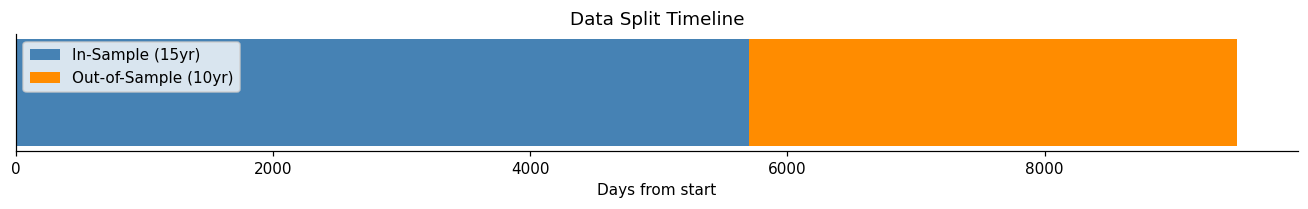

In [2]:
# ── Load, sanitize & split data ──────────────────────────────────────────
df = pd.read_excel('/content/Consolidated_cleaned.xlsx')
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

# Fix 1: Sanitize non-positive prices to eliminate RuntimeWarning in log()
df = df.where(df > 0, np.nan).ffill().dropna()

# Log returns for time-series econometrics (ADF, GARCH, Markov Switching)
returns_full = np.log(df / df.shift(1)).dropna()
# Simple returns for exact linear cross-sectional portfolio aggregation
simple_returns_full = df.pct_change().loc[returns_full.index]

split_date  = returns_full.index[int(len(returns_full) * 0.60)]
returns     = returns_full[returns_full.index <= split_date].copy()
returns_oos = returns_full[returns_full.index  > split_date].copy()

simple_returns     = simple_returns_full[simple_returns_full.index <= split_date].copy()
simple_returns_oos = simple_returns_full[simple_returns_full.index  > split_date].copy()

print(f"Total data   : {returns_full.index[0].date()} → {returns_full.index[-1].date()}  ({len(returns_full)} days)")
print(f"In-sample    : {returns.index[0].date()} → {returns.index[-1].date()}  ({len(returns)} days)")
print(f"Out-of-sample: {returns_oos.index[0].date()} → {returns_oos.index[-1].date()}  ({len(returns_oos)} days)")

# ── Timeline chart ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 2))
ax.barh(0, (split_date - returns.index[0]).days,           left=0,    color='steelblue',  height=0.5, label='In-Sample (15yr)')
ax.barh(0, (returns_oos.index[-1] - split_date).days,      left=(split_date - returns.index[0]).days, color='darkorange', height=0.5, label='Out-of-Sample (10yr)')
ax.set_yticks([])
ax.set_xlabel('Days from start')
ax.set_title('Data Split Timeline')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

---
## Part 1 — Exploratory Data Analysis

### 1.1 Descriptive Statistics

In [3]:
stats_table = pd.DataFrame({
    'Mean':     returns.mean(),
    'Std Dev':  returns.std(),
    'Median':   returns.median(),
    'Skewness': returns.apply(skew),
    'Kurtosis': returns.apply(kurtosis),
    'Min':      returns.min(),
    'Max':      returns.max()
})
print(stats_table.round(6))

                    Mean   Std Dev    Median  Skewness    Kurtosis       Min  \
ALUMINUM DATA  -0.000002  0.025277  0.000000 -0.206911  123.510081 -0.555487   
COFFEE DATA     0.000040  0.036799  0.000000  0.063616   28.819513 -0.424654   
COPPER DATA     0.000256  0.035926  0.000310 -0.440953   93.928389 -0.655655   
CORN DATA       0.000148  0.033597  0.000000 -0.236964   41.493535 -0.411019   
CRUDE OIL DATA  0.000083  0.040244  0.000604 -0.281102   69.007975 -0.605767   
GOLD DATA       0.000345  0.019077  0.000370  0.033057   27.385443 -0.197394   
SOYBEAN DATA    0.000194  0.030626  0.000886 -0.233399   40.923483 -0.337224   

                     Max  
ALUMINUM DATA   0.536121  
COFFEE DATA     0.416512  
COPPER DATA     0.628614  
CORN DATA       0.398226  
CRUDE OIL DATA  0.605583  
GOLD DATA       0.186552  
SOYBEAN DATA    0.329538  


### 1.2 Return Distributions — All Commodities

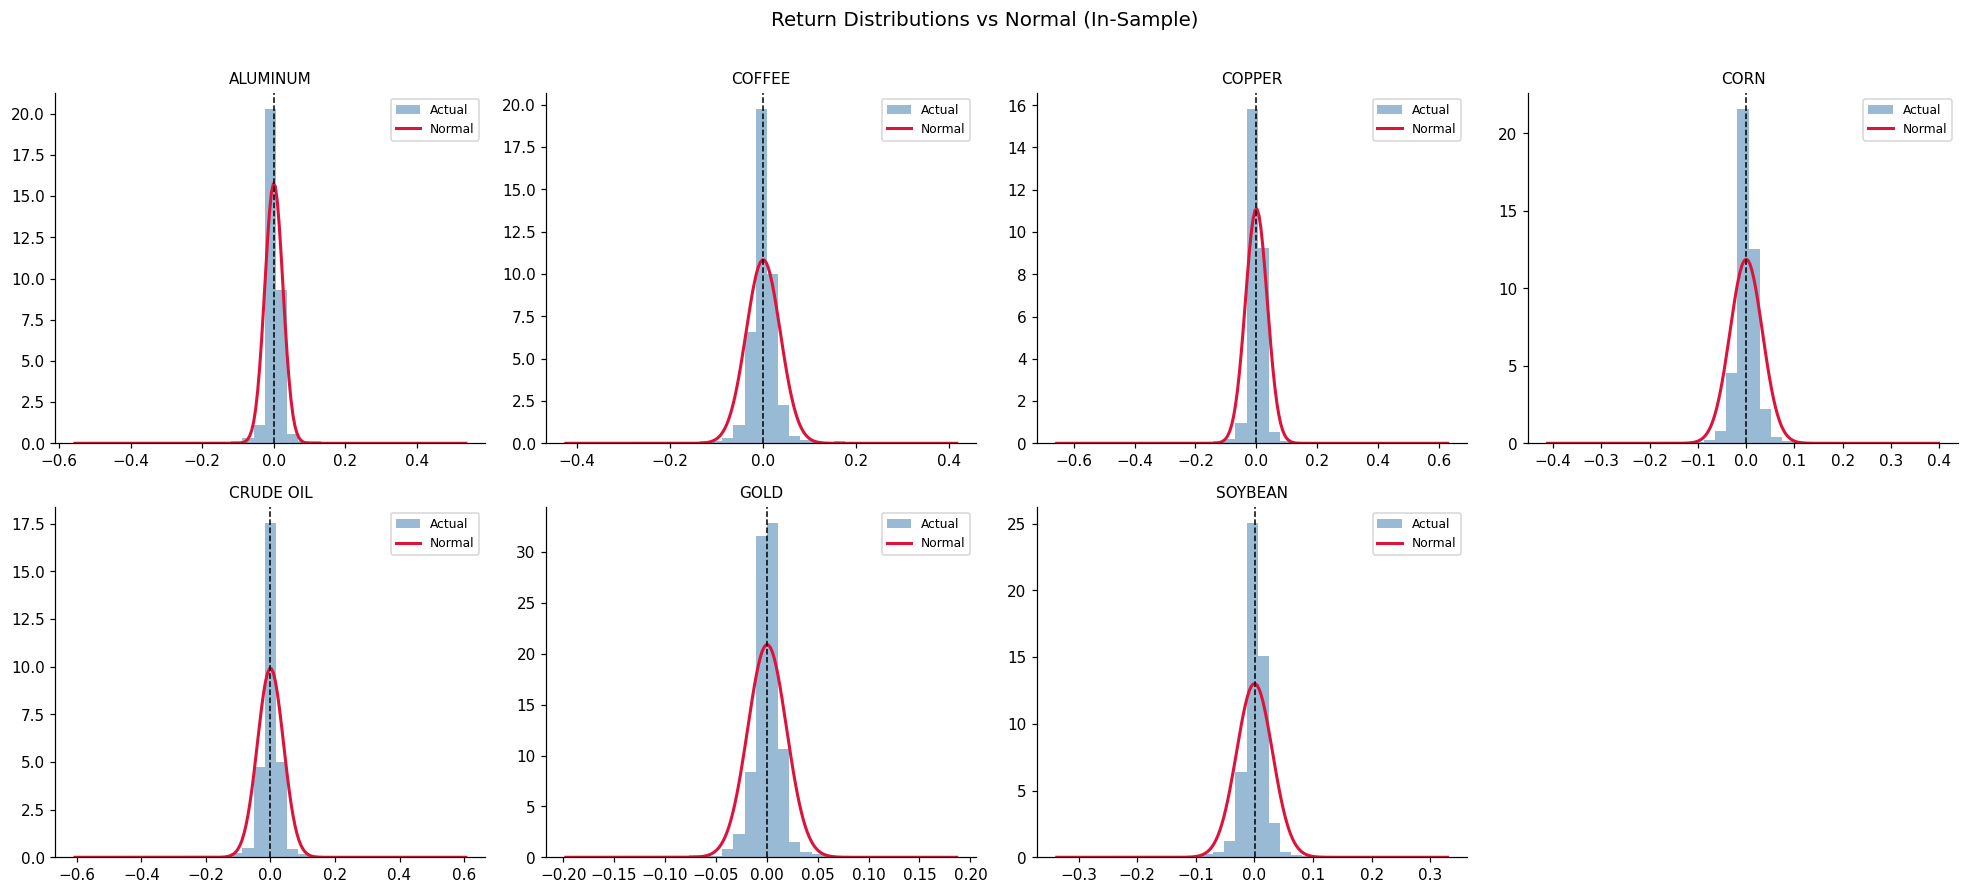

In [4]:
n = len(returns.columns)
cols_per_row = 4
rows = (n + cols_per_row - 1) // cols_per_row

fig, axes = plt.subplots(rows, cols_per_row, figsize=(18, rows * 4))
axes = axes.flatten()

for i, col in enumerate(returns.columns):
    data = returns[col]
    axes[i].hist(data, bins=35, density=True, alpha=0.55, color='steelblue', label='Actual')
    mu, sigma = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 200)
    axes[i].plot(x, norm.pdf(x, mu, sigma), color='crimson', linewidth=2, label='Normal')
    axes[i].axvline(mu, linestyle='--', color='black', linewidth=1)
    axes[i].set_title(col.replace(' DATA',''), fontsize=10)
    axes[i].legend(fontsize=8)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Return Distributions vs Normal (In-Sample)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 1.3 Jarque-Bera Normality Test

               JB Statistic p-value        Result
ALUMINUM DATA    2550748.29     0.0  Non-Normal ✗
COFFEE DATA       138879.99     0.0  Non-Normal ✗
COPPER DATA      1475332.65     0.0  Non-Normal ✗
CORN DATA         287922.39     0.0  Non-Normal ✗
CRUDE OIL DATA    796315.75     0.0  Non-Normal ✗
GOLD DATA         125400.71     0.0  Non-Normal ✗
SOYBEAN DATA      280065.49     0.0  Non-Normal ✗


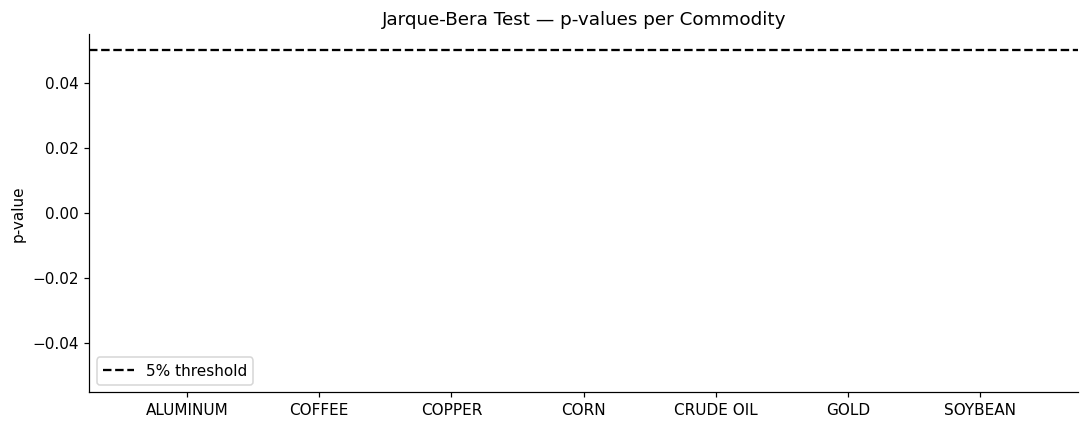

In [5]:
jb_results = {}
for col in returns.columns:
    jb, p = jarque_bera(returns[col])
    jb_results[col] = {'JB Statistic': round(jb, 2), 'p-value': round(p, 4),
                       'Result': 'Non-Normal ✗' if p < 0.05 else 'Normal ✓'}

jb_df = pd.DataFrame(jb_results).T
print(jb_df)

# Visual
fig, ax = plt.subplots(figsize=(10, 4))
pvals = [jarque_bera(returns[c])[1] for c in returns.columns]
colors = ['crimson' if p < 0.05 else 'steelblue' for p in pvals]
ax.bar([c.replace(' DATA','') for c in returns.columns], pvals, color=colors, alpha=0.8)
ax.axhline(0.05, linestyle='--', color='black', label='5% threshold')
ax.set_ylabel('p-value')
ax.set_title('Jarque-Bera Test — p-values per Commodity')
ax.legend()
plt.tight_layout()


### 1.4 Correlation Heatmap

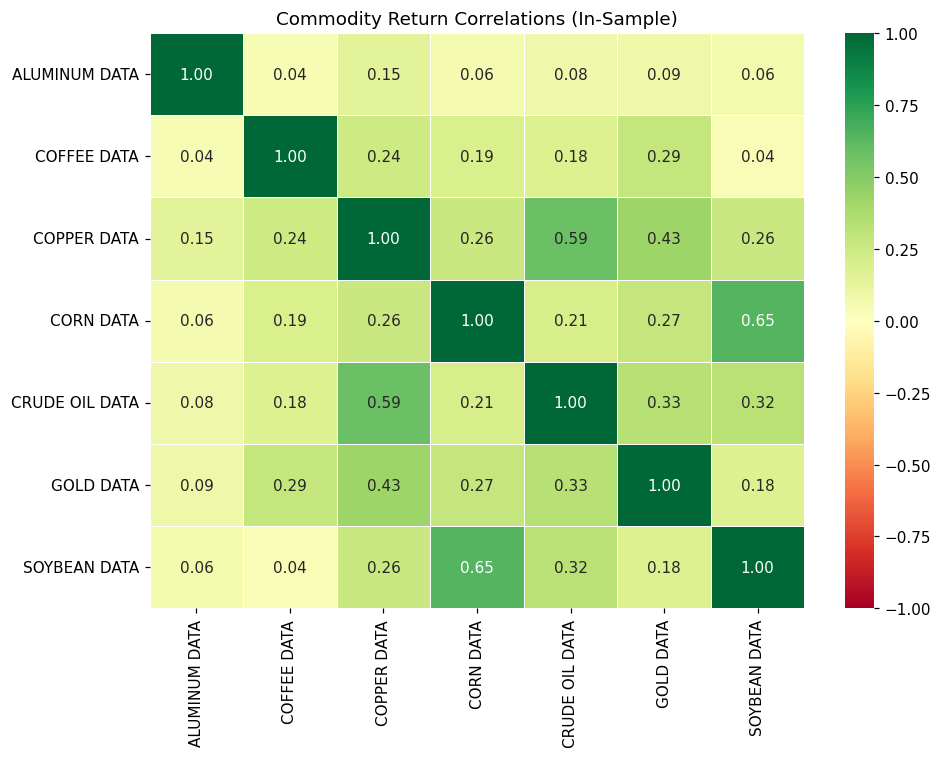

In [6]:
corr = returns.corr()

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(9, 7))

# Generate the full heatmap by removing the mask parameter
sns.heatmap(corr, annot=True, cmap='RdYlGn', fmt='.2f',
            vmin=-1, vmax=1, linewidths=0.5, ax=ax)

ax.set_title('Commodity Return Correlations (In-Sample)', fontsize=12)
plt.tight_layout()
plt.show()

### 1.5 ADF Stationarity Test

In [7]:
adf_results = {}
for col in returns.columns:
    r = adfuller(returns[col], autolag='AIC')
    adf_results[col] = {'ADF Stat': round(r[0], 4), 'p-value': round(r[1], 4),
                        'Result': 'Stationary ✓' if r[1] < 0.05 else 'Non-Stationary ✗'}

print(pd.DataFrame(adf_results).T)

               ADF Stat p-value        Result
ALUMINUM DATA   -40.217     0.0  Stationary ✓
COFFEE DATA    -15.3417     0.0  Stationary ✓
COPPER DATA    -10.1422     0.0  Stationary ✓
CORN DATA      -30.0121     0.0  Stationary ✓
CRUDE OIL DATA -11.7822     0.0  Stationary ✓
GOLD DATA       -14.152     0.0  Stationary ✓
SOYBEAN DATA   -12.0122     0.0  Stationary ✓


---
## Part 2 — Volatility Modelling

### 2.1 Market Index & ARCH Test

In [8]:
market_return = returns.mean(axis=1)

arch_test = het_arch(market_return)
print(f"ARCH LM Statistic : {arch_test[0]:.4f}")
print(f"p-value           : {arch_test[1]:.4f}")
print("Conclusion        :", "ARCH effects present — GARCH modelling justified" if arch_test[1] < 0.05 else "No ARCH effects")

ARCH LM Statistic : 1577.7432
p-value           : 0.0000
Conclusion        : ARCH effects present — GARCH modelling justified


### 2.2 GARCH(1,1) — Conditional Volatility

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7466.33
Distribution:                  Normal   AIC:                           14940.7
Method:            Maximum Likelihood   BIC:                           14965.8
                                        No. Observations:                 4013
Date:                Sat, Nov 07 2026   Df Residuals:                     4012
Time:                        08:47:38   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu            -0.0367  4.841e-02     -0.759      0.448 [ -0.132,

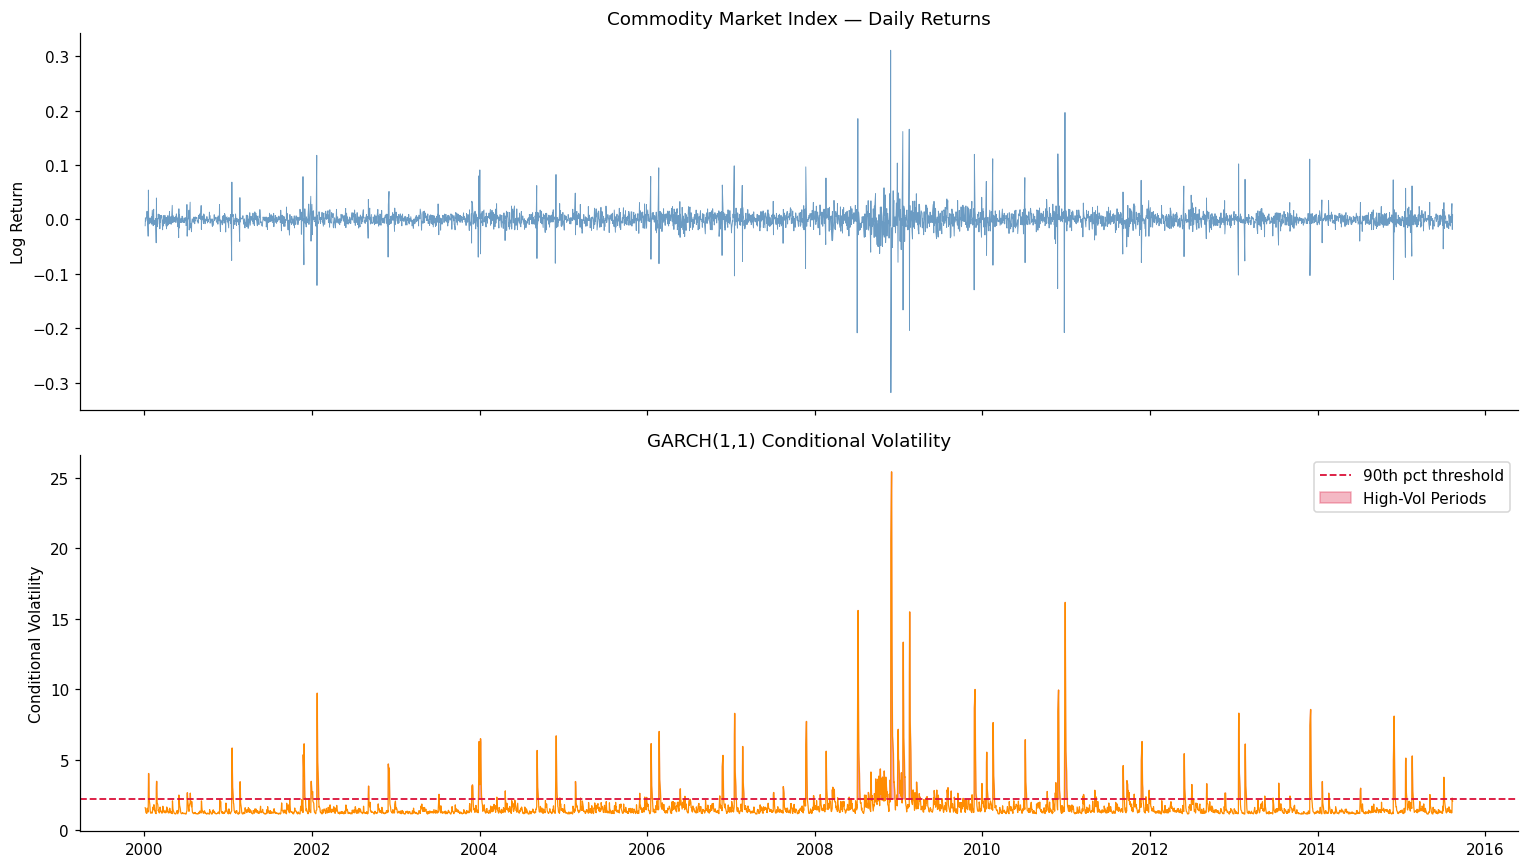

High-vol threshold (90th pct): 2.2218
Days in high-vol regime: 402


In [9]:
garch      = arch_model(market_return * 100, vol='Garch', p=1, q=1)
garch_result = garch.fit(disp='off')
print(garch_result.summary())

volatility = garch_result.conditional_volatility
threshold  = volatility.quantile(0.90)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(market_return.index, market_return, color='steelblue', linewidth=0.6, alpha=0.8)
axes[0].set_title('Commodity Market Index — Daily Returns')
axes[0].set_ylabel('Log Return')

axes[1].plot(volatility.index, volatility, color='darkorange', linewidth=0.8)
axes[1].axhline(threshold, linestyle='--', color='crimson', linewidth=1.2, label=f'90th pct threshold')
axes[1].fill_between(volatility.index, volatility, threshold,
                     where=(volatility > threshold), alpha=0.3, color='crimson', label='High-Vol Periods')
axes[1].set_title('GARCH(1,1) Conditional Volatility')
axes[1].set_ylabel('Conditional Volatility')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"High-vol threshold (90th pct): {threshold:.4f}")
print(f"Days in high-vol regime: {(volatility > threshold).sum()}")

---
## Part 3 — Static Markowitz Benchmark

### 3.1 Efficient Frontier

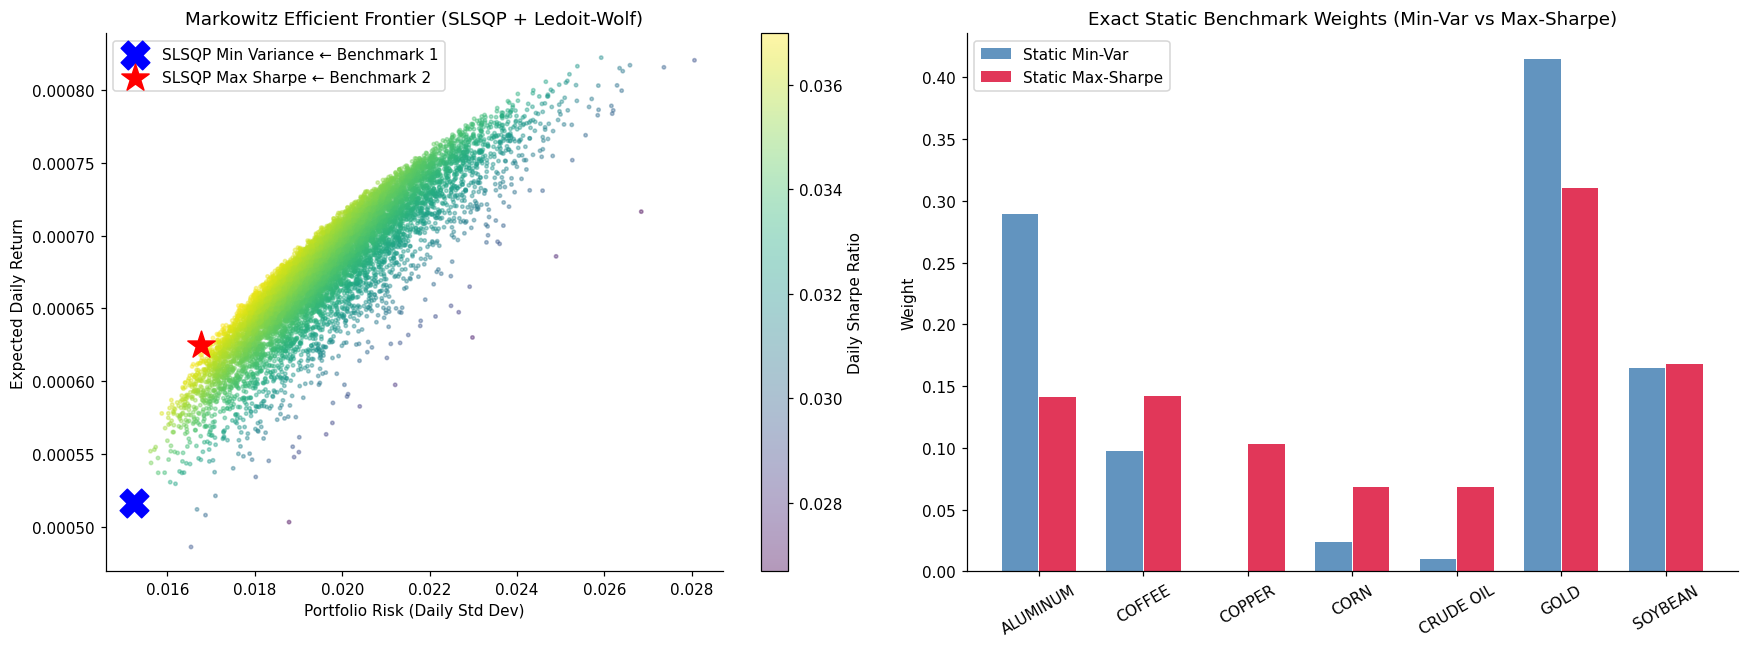

In [10]:
np.random.seed(42)
# Use simple returns and Ledoit-Wolf shrinkage for exact Markowitz optimization
mean_returns = simple_returns.mean().values
lw_static    = LedoitWolf().fit(simple_returns.values)
cov_matrix   = lw_static.covariance_
num_assets   = len(mean_returns)

def portfolio_performance(w, mu=mean_returns, cov=cov_matrix):
    ret  = np.dot(w, mu)
    risk = np.sqrt(np.dot(w.T, np.dot(cov, w)))
    return ret, risk

# Exact SLSQP Optimization for Static Min-Variance & Static Max-Sharpe
bounds = tuple((0.0, 1.0) for _ in range(num_assets))
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},)
init_w = np.repeat(1.0 / num_assets, num_assets)

res_min_var = minimize(lambda w: portfolio_performance(w)[1], init_w,
                       method='SLSQP', bounds=bounds, constraints=constraints)
static_weights = res_min_var.x
mv_ret, mv_risk = portfolio_performance(static_weights)

res_max_sr = minimize(lambda w: -portfolio_performance(w)[0] / max(portfolio_performance(w)[1], 1e-8),
                      init_w, method='SLSQP', bounds=bounds, constraints=constraints)
static_max_sr_weights = res_max_sr.x
ms_ret, ms_risk = portfolio_performance(static_max_sr_weights)

# Monte Carlo cloud for visual context
results = np.zeros((3, 10000))
for i in range(10000):
    w = np.random.random(num_assets); w /= w.sum()
    ret, risk = portfolio_performance(w)
    results[0, i], results[1, i], results[2, i] = ret, risk, ret / risk

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(results[1, :], results[0, :], c=results[2, :], cmap='viridis', alpha=0.4, s=5)
axes[0].scatter(mv_risk, mv_ret, marker='X', s=350, color='blue', zorder=5, label='SLSQP Min Variance ← Benchmark 1')
axes[0].scatter(ms_risk, ms_ret, marker='*', s=350, color='red',  zorder=5, label='SLSQP Max Sharpe ← Benchmark 2')
plt.colorbar(sc, ax=axes[0], label='Daily Sharpe Ratio')
axes[0].set_xlabel('Portfolio Risk (Daily Std Dev)'); axes[0].set_ylabel('Expected Daily Return')
axes[0].set_title('Markowitz Efficient Frontier (SLSQP + Ledoit-Wolf)'); axes[0].legend()

x_pos = np.arange(num_assets)
axes[1].bar(x_pos - 0.18, static_weights, width=0.35, color='steelblue', alpha=0.85, label='Static Min-Var')
axes[1].bar(x_pos + 0.18, static_max_sr_weights, width=0.35, color='crimson', alpha=0.85, label='Static Max-Sharpe')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([c.replace(' DATA','') for c in returns.columns], rotation=30)
axes[1].set_title('Exact Static Benchmark Weights (Min-Var vs Max-Sharpe)')
axes[1].set_ylabel('Weight'); axes[1].legend()

plt.tight_layout()
plt.show()

---
## Part 4 — Markov Regime Switching

### 4.1 BIC Model Selection — Justifying k=4

k=2: BIC=-24107.89 | Min Regime Obs (Filtered)=216 days
k=3: BIC=-24259.10 | Min Regime Obs (Filtered)=130 days
k=4: BIC=-24373.74 | Min Regime Obs (Filtered)=65 days

Optimal regimes by raw BIC: k=4


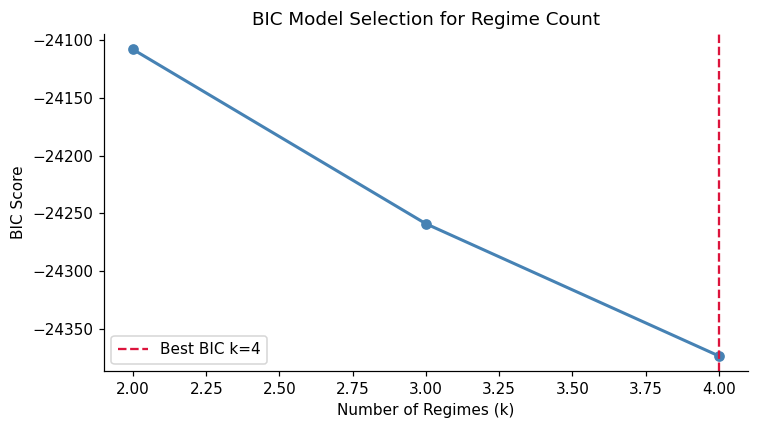

In [11]:
# Keep exact trading-day adjacency; pass integer-indexed array to avoid statsmodels ValueWarning
market_return_clean = market_return.dropna()
bic_scores = {}

for k in [2, 3, 4]:
    try:
        m = sm.tsa.MarkovAutoregression(market_return_clean.values, k_regimes=k,
                                        order=1, switching_variance=True)
        r = m.fit(method='bfgs', maxiter=500, disp=False)
        # Check minimum regime sample size using causal filtered probabilities
        f_reg = pd.Series(r.filtered_marginal_probabilities.argmax(axis=1))
        min_obs = f_reg.value_counts().min() if len(f_reg.unique()) == k else 0
        bic_scores[k] = r.bic
        print(f"k={k}: BIC={r.bic:.2f} | Min Regime Obs (Filtered)={min_obs} days")
    except Exception as e:
        print(f"k={k}: failed ({e})")

best_k = min(bic_scores, key=bic_scores.get)
print(f"\nOptimal regimes by raw BIC: k={best_k}")

plt.figure(figsize=(7, 4))
plt.plot(list(bic_scores.keys()), list(bic_scores.values()), marker='o', color='steelblue', linewidth=2)
plt.axvline(best_k, linestyle='--', color='crimson', label=f'Best BIC k={best_k}')
plt.xlabel('Number of Regimes (k)'); plt.ylabel('BIC Score')
plt.title('BIC Model Selection for Regime Count')
plt.legend()
plt.tight_layout()
plt.show()

### 4.2 Fit 4-Regime Markov Model (In-Sample)

In [12]:
# Fix 3: Use switching_ar=False (mean + variance switching) so k regimes represent persistent volatility/drift states
# rather than 1-day AR(-0.96) outlier absorbers with NaN standard errors in the transition matrix.
markov_model = sm.tsa.MarkovAutoregression(
    market_return_clean.values, k_regimes=best_k, order=1,
    switching_ar=False, switching_trend=True, switching_variance=True
)
try:
    model_fit = markov_model.fit(method='bfgs', maxiter=2000, disp=False)
except Exception:
    print("BFGS failed — switching to Powell...")
    model_fit = markov_model.fit(method='powell', maxiter=2000, disp=False)

print(model_fit.summary())

                         Markov Switching Model Results                         
Dep. Variable:                        y   No. Observations:                 4012
Model:             MarkovAutoregression   Log Likelihood               12197.859
Date:                  Sat, 07 Nov 2026   AIC                         -24353.717
Time:                          08:50:21   BIC                         -24221.479
Sample:                               0   HQIC                        -24306.849
                                 - 4012                                         
Covariance Type:                 approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -3.77e-05      0.000     -0.198      0.843      -0.000       0.000
sigma2      4.901e-05   3.74e-06    

### 4.3 Regime Classification & Statistics

=== CAUSAL FILTERED REGIME STATISTICS ===
        Mean Return  Volatility  Frequency (days)  Avg Duration
Regime                                                         
0          0.000010    0.006610              1724     11.808219
1         -0.001708    0.029269               226      2.597701
2          0.000584    0.011265              1990     10.815217
3         -0.002398    0.113322                72      1.894737


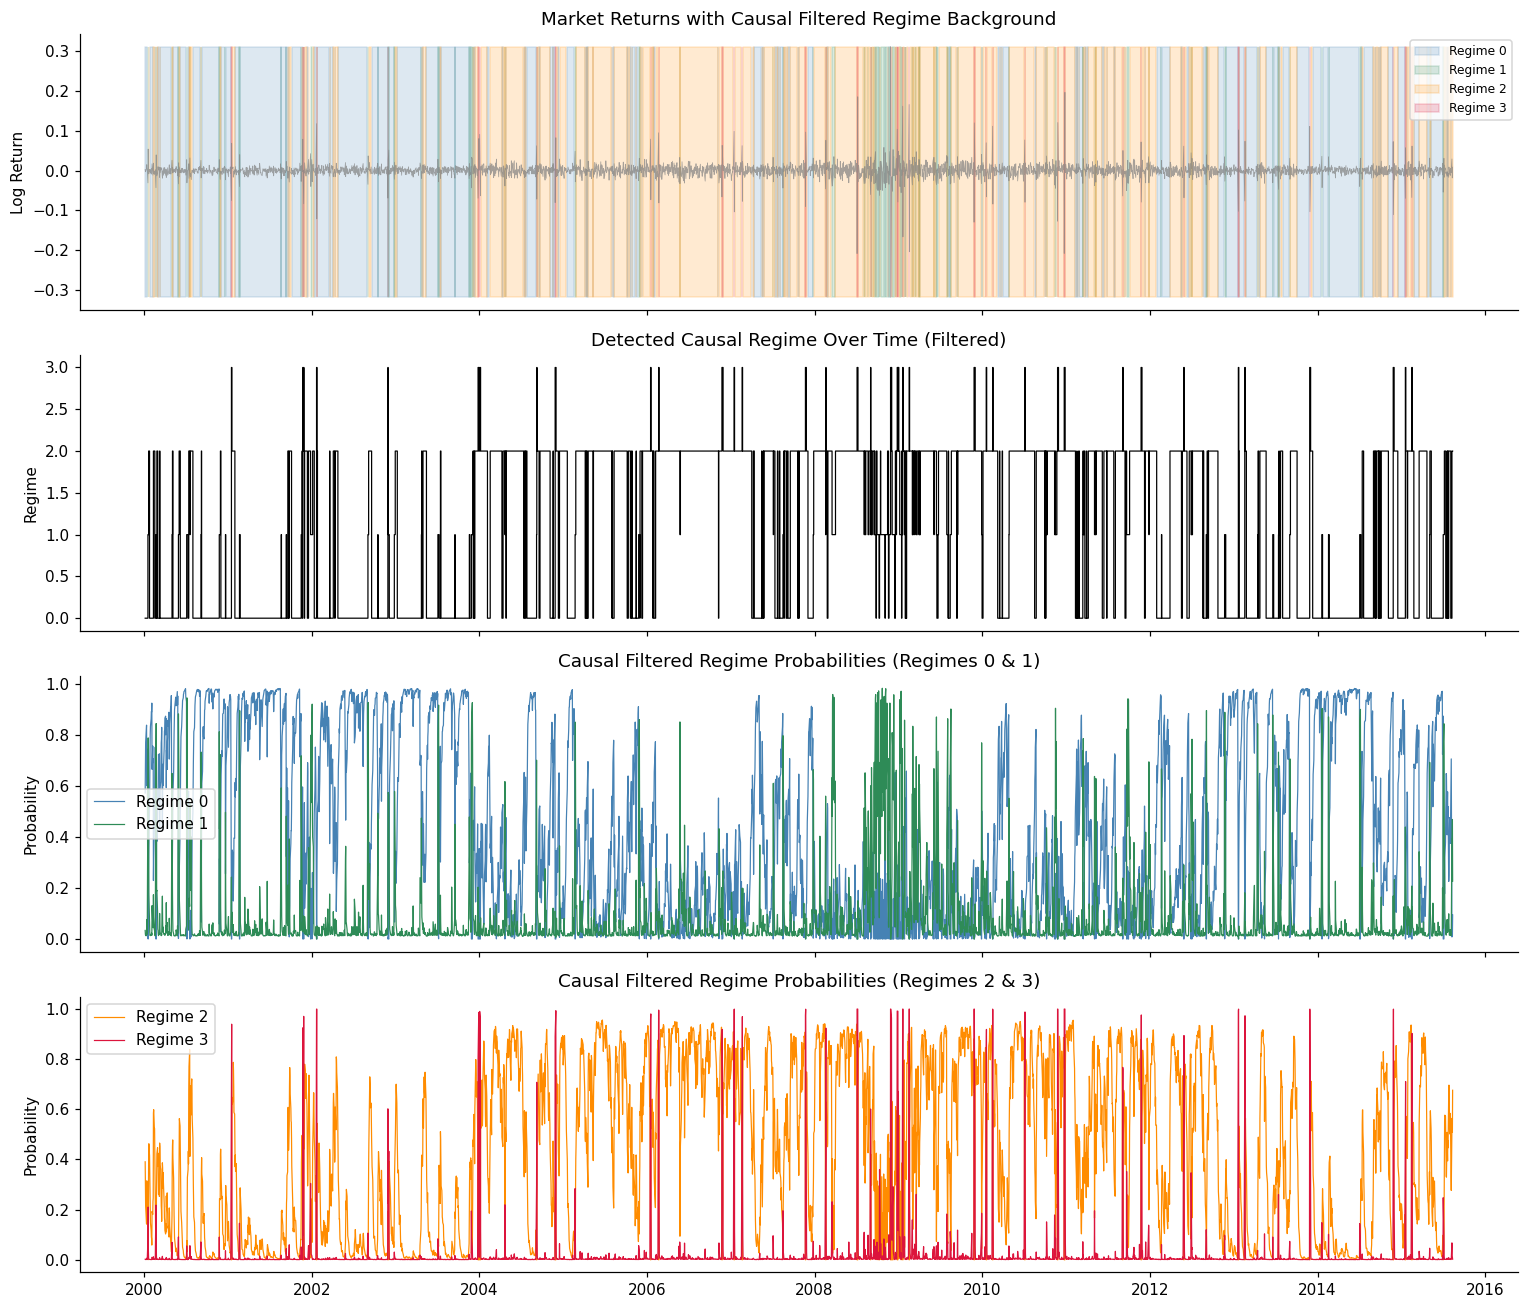

In [13]:
# Fix 4: Extract strictly causal FILTERED marginal probabilities P(S_t = k | F_t) to eliminate look-ahead bias
probs_arr = model_fit.filtered_marginal_probabilities
probs = pd.DataFrame(probs_arr, index=market_return_clean.index[1:],
                     columns=[f'Regime {i}' for i in range(best_k)])

# Raw contemporaneous regime (at close of day t) and 1-day lagged causal trading regime (for day t+1 allocation)
regime_contemp = pd.Series(probs_arr.argmax(axis=1), index=probs.index)
regime_lagged  = regime_contemp.shift(1).bfill().astype(int)
regime         = regime_contemp  # kept for regime descriptive statistics on historical states

aligned_returns        = returns.loc[regime.index]
aligned_simple_returns = simple_returns.loc[regime.index]

regime_df = pd.DataFrame({'Return': market_return_clean.loc[regime.index], 'Regime': regime})
regime_df['Change'] = regime_df['Regime'] != regime_df['Regime'].shift()
regime_df['Spell']  = regime_df['Change'].cumsum()

regime_stats = pd.DataFrame({
    'Mean Return':      regime_df.groupby('Regime')['Return'].mean(),
    'Volatility':       regime_df.groupby('Regime')['Return'].std(),
    'Frequency (days)': regime_df['Regime'].value_counts().sort_index(),
    'Avg Duration':     regime_df.groupby(['Regime','Spell']).size().groupby(level=0).mean()
})
print("=== CAUSAL FILTERED REGIME STATISTICS ===")
print(regime_stats.round(6))

# ── 4-panel regime visual ─────────────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
colors = ['steelblue','seagreen','darkorange','crimson']

# Panel 1: returns with regime background shading
axes[0].plot(regime_df.index, regime_df['Return'], color='grey', linewidth=0.5, alpha=0.7)
for r, col in zip(sorted(regime.unique()), colors):
    mask = (regime == r)
    axes[0].fill_between(regime.index, regime_df['Return'].min(), regime_df['Return'].max(),
                         where=mask, alpha=0.18, color=col, label=f'Regime {r}')
axes[0].set_title('Market Returns with Causal Filtered Regime Background')
axes[0].set_ylabel('Log Return'); axes[0].legend(loc='upper right', fontsize=8)

# Panel 2: regime classification
axes[1].plot(regime.index, regime, drawstyle='steps-post', color='black', linewidth=0.8)
axes[1].set_title('Detected Causal Regime Over Time (Filtered)')
axes[1].set_ylabel('Regime')

# Panels 3-4: causal filtered probabilities
for r in [0, 1]:
    if r < best_k:
        axes[2].plot(probs.index, probs.iloc[:, r], label=f'Regime {r}', color=colors[r], linewidth=0.8)
axes[2].set_title('Causal Filtered Regime Probabilities (Regimes 0 & 1)')
axes[2].set_ylabel('Probability'); axes[2].legend()

for r in [2, 3]:
    if r < best_k:
        axes[3].plot(probs.index, probs.iloc[:, r], label=f'Regime {r}', color=colors[r], linewidth=0.8)
axes[3].set_title('Causal Filtered Regime Probabilities (Regimes 2 & 3)')
axes[3].set_ylabel('Probability'); axes[3].legend()

plt.tight_layout()
plt.show()

### 4.4 Regime-Specific Covariance — High vs Low Volatility

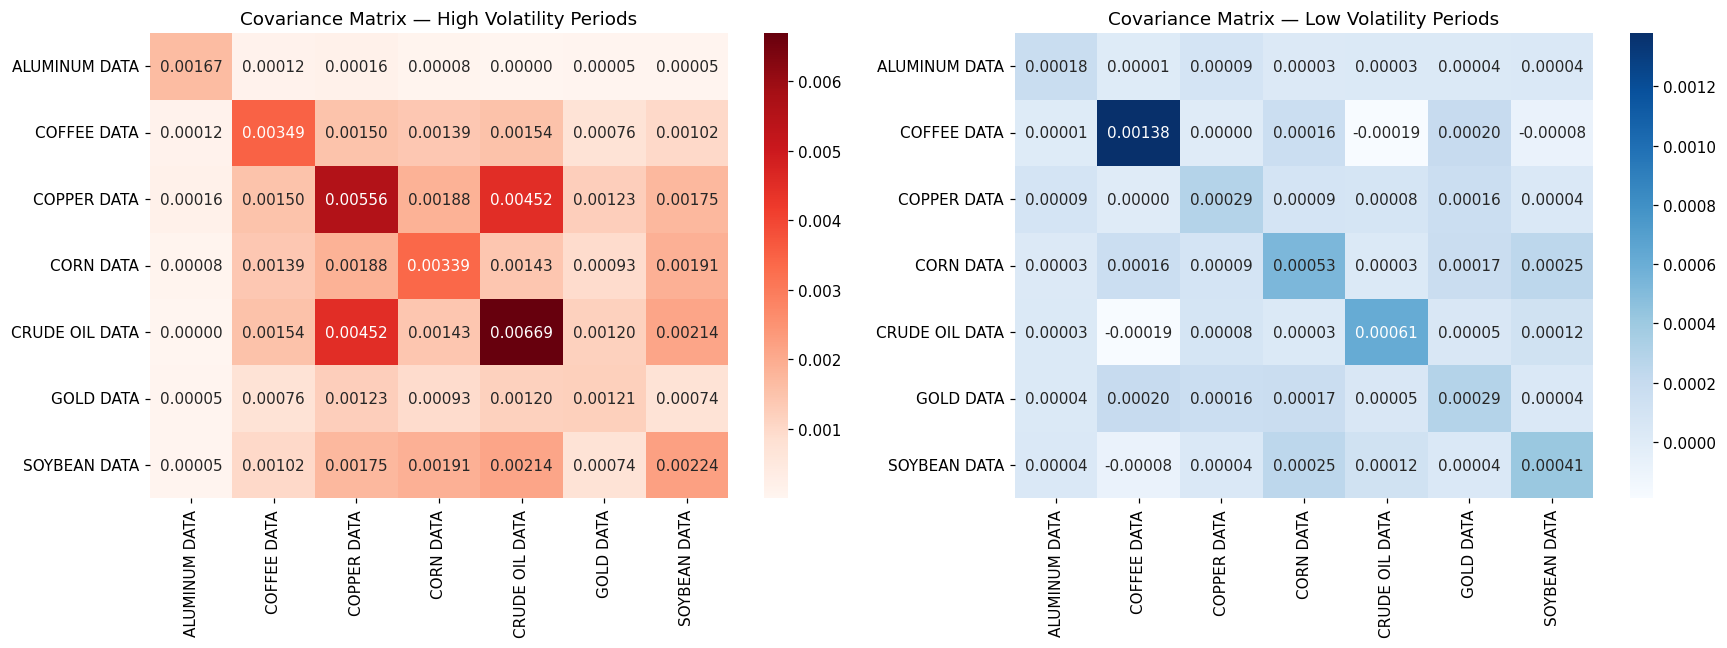

If matrices differ significantly → regime-specific covariance is essential.


In [14]:
high_vol_mask = volatility > volatility.quantile(0.90)
low_vol_mask  = volatility <= volatility.quantile(0.10)
common_high   = returns.index.intersection(high_vol_mask[high_vol_mask].index)
common_low    = returns.index.intersection(low_vol_mask[low_vol_mask].index)

cov_high = returns.loc[common_high].cov()
cov_low  = returns.loc[common_low].cov()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cov_high, annot=True, fmt='.5f', cmap='Reds',  ax=axes[0])
axes[0].set_title('Covariance Matrix — High Volatility Periods')
sns.heatmap(cov_low,  annot=True, fmt='.5f', cmap='Blues', ax=axes[1])
axes[1].set_title('Covariance Matrix — Low Volatility Periods')
plt.tight_layout()
plt.show()
print("If matrices differ significantly → regime-specific covariance is essential.")

---
## Part 5 — Regime-Specific Portfolio Optimization

### 5.1 Optimal Weights Per Regime

In [15]:
# Fix 5: Replace 5,000 random Dirichlet draws & noisy sample covariance with
# Ledoit-Wolf Shrinkage Covariance + Exact SLSQP Optimization per regime
regime_weights = {}
n_assets = len(aligned_simple_returns.columns)
bounds = tuple((0.0, 1.0) for _ in range(n_assets))
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},)
init_w = np.repeat(1.0 / n_assets, n_assets)

for r in sorted(regime.unique()):
    subset = aligned_simple_returns[regime == r]
    mu = subset.mean().values
    # Apply Ledoit-Wolf shrinkage to regularize small-sample regime covariance matrices
    cov = LedoitWolf().fit(subset.values).covariance_ if len(subset) > n_assets else np.cov(subset.values.T)

    # If a crash regime has negative drift across all assets, minimize variance defensively
    if np.max(mu) <= 0:
        opt = minimize(lambda w: np.sqrt(np.dot(w.T, np.dot(cov, w))),
                       init_w, method='SLSQP', bounds=bounds, constraints=constraints)
    else:
        opt = minimize(lambda w: -np.dot(w, mu) / max(np.sqrt(np.dot(w.T, np.dot(cov, w))), 1e-8),
                       init_w, method='SLSQP', bounds=bounds, constraints=constraints)
    best_w = opt.x / np.sum(opt.x)
    ret_r  = np.dot(best_w, mu)
    risk_r = np.sqrt(np.dot(best_w.T, np.dot(cov, best_w)))
    best_sr = (ret_r / risk_r) * np.sqrt(252) if risk_r > 0 else 0.0
    regime_weights[r] = best_w
    print(f"Regime {r} (N={len(subset)}d) — Annualized Regime Sharpe: {best_sr:.4f}")

regime_weight_df = pd.DataFrame(regime_weights, index=returns.columns)
regime_weight_df.columns = [f'Regime {r}' for r in sorted(regime_weights)]
print("\nRegime-Specific Optimal Weights (SLSQP + Ledoit-Wolf):")
print(regime_weight_df.round(4))

Regime 0 (N=1724d) — Annualized Regime Sharpe: 0.8798
Regime 1 (N=226d) — Annualized Regime Sharpe: 0.8358
Regime 2 (N=1990d) — Annualized Regime Sharpe: 1.3244
Regime 3 (N=72d) — Annualized Regime Sharpe: 2.1041

Regime-Specific Optimal Weights (SLSQP + Ledoit-Wolf):
                Regime 0  Regime 1  Regime 2  Regime 3
ALUMINUM DATA     0.0068       0.0    0.0179    0.1959
COFFEE DATA       0.0000       1.0    0.1681    0.0000
COPPER DATA       0.0000       0.0    0.2448    0.2751
CORN DATA         0.0844       0.0    0.1684    0.0000
CRUDE OIL DATA    0.0556       0.0    0.0672    0.3268
GOLD DATA         0.4093       0.0    0.1666    0.2021
SOYBEAN DATA      0.4439       0.0    0.1670    0.0000


### 5.2 Allocation Comparison Across Regimes

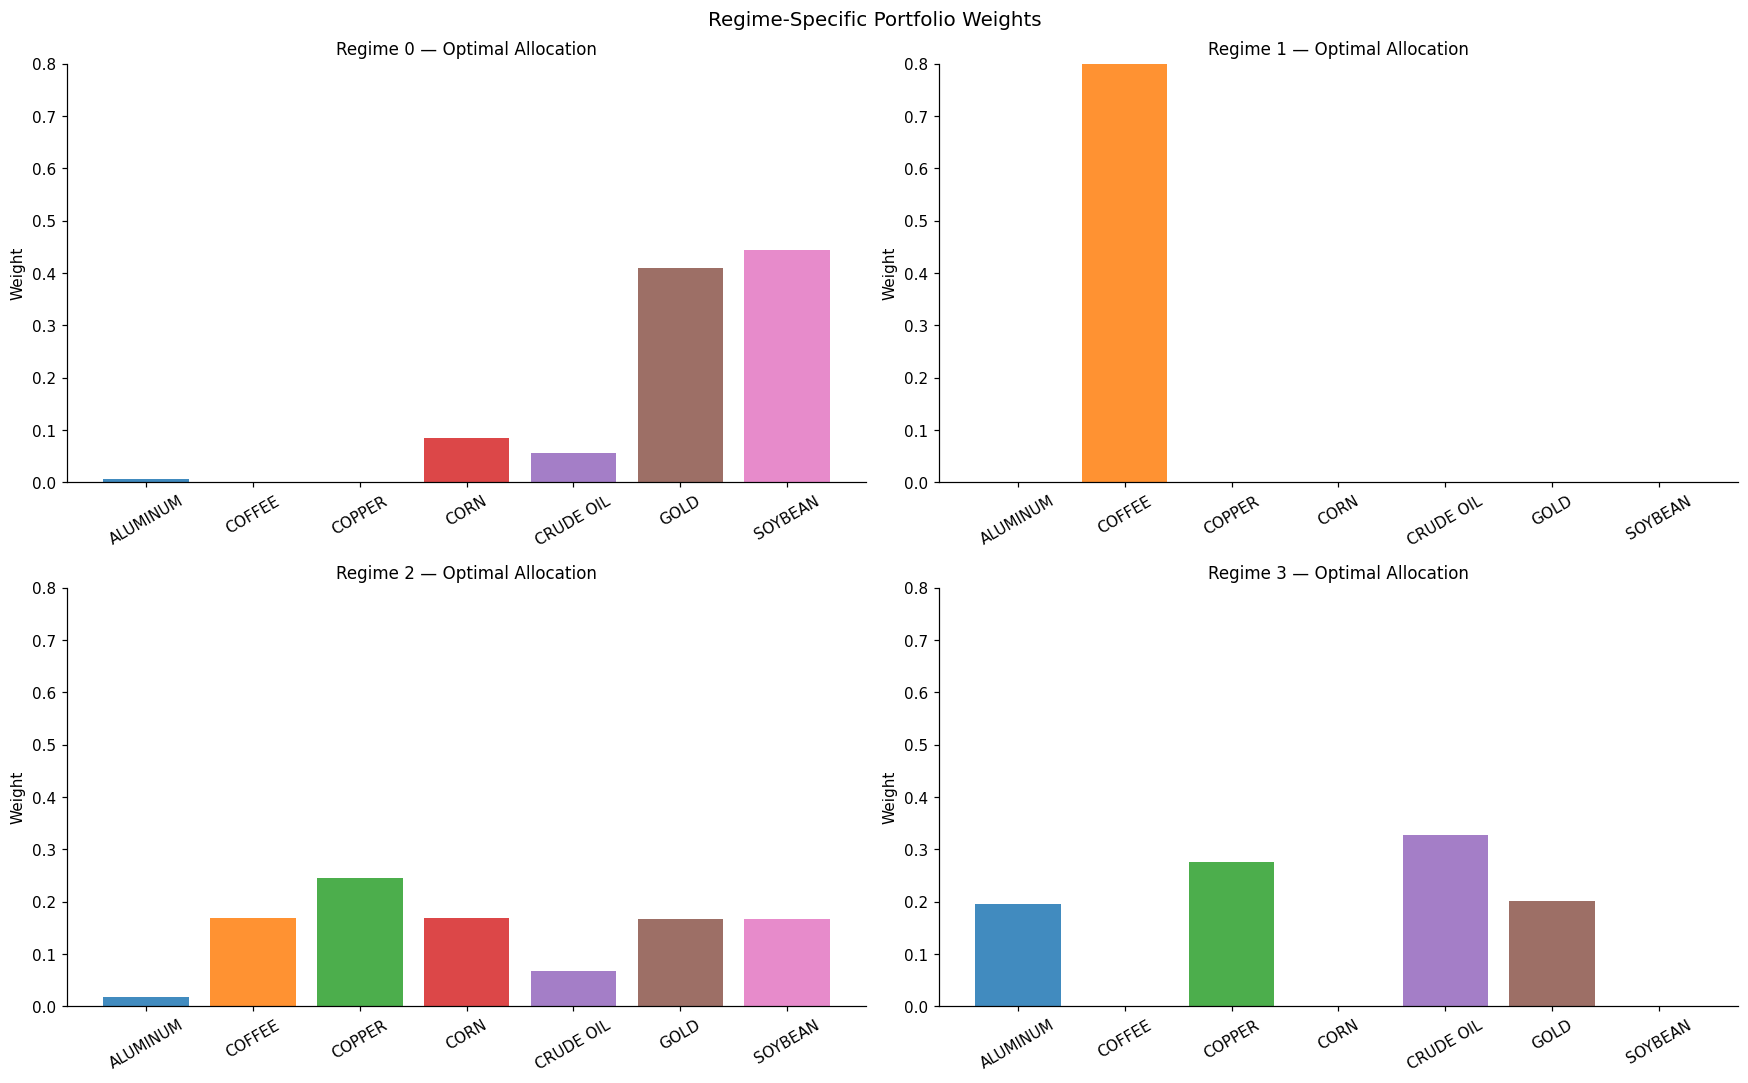

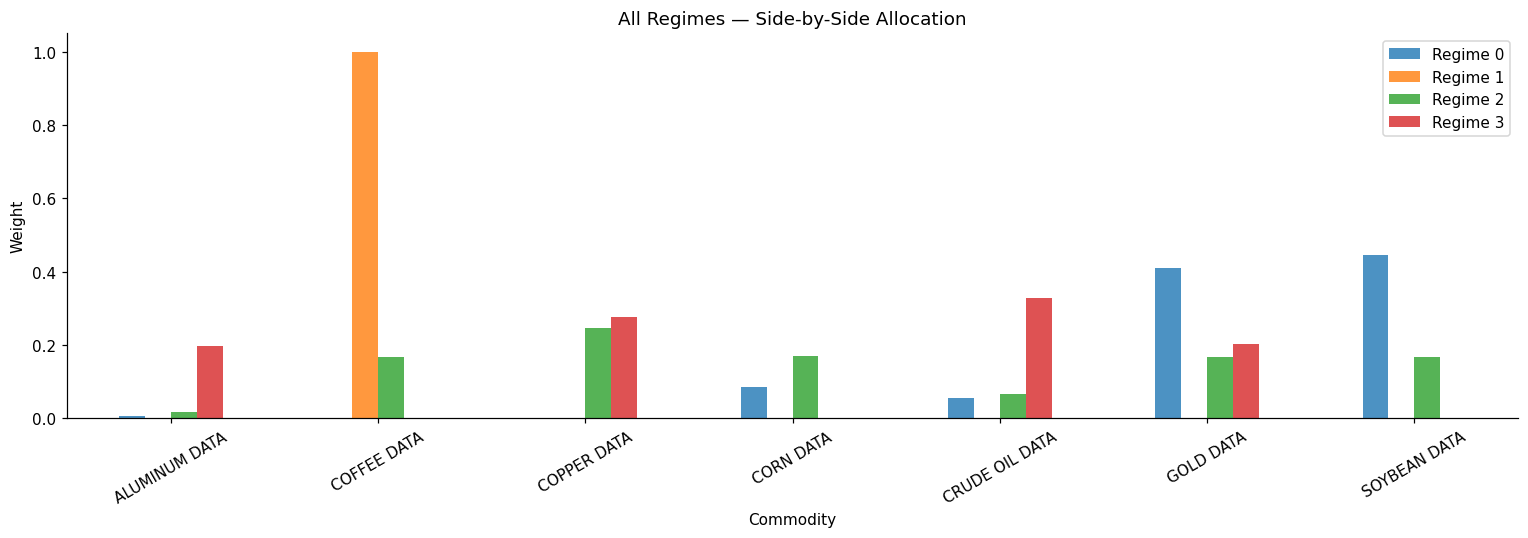

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
colors_bar = plt.cm.tab10.colors

for i, r in enumerate(sorted(regime_weights.keys())):
    axes[i].bar([c.replace(' DATA','') for c in returns.columns],
                regime_weights[r], color=colors_bar[:len(returns.columns)], alpha=0.85)
    axes[i].set_title(f'Regime {r} — Optimal Allocation', fontsize=11)
    axes[i].set_ylabel('Weight')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].set_ylim(0, 0.8)

plt.suptitle('Regime-Specific Portfolio Weights', fontsize=13)
plt.tight_layout()
plt.show()

# Grouped bar — all regimes side by side
regime_weight_df.plot(kind='bar', figsize=(14, 5), alpha=0.8)
plt.title('All Regimes — Side-by-Side Allocation')
plt.ylabel('Weight'); plt.xlabel('Commodity')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 5.3 Dynamic Weight History Through Time

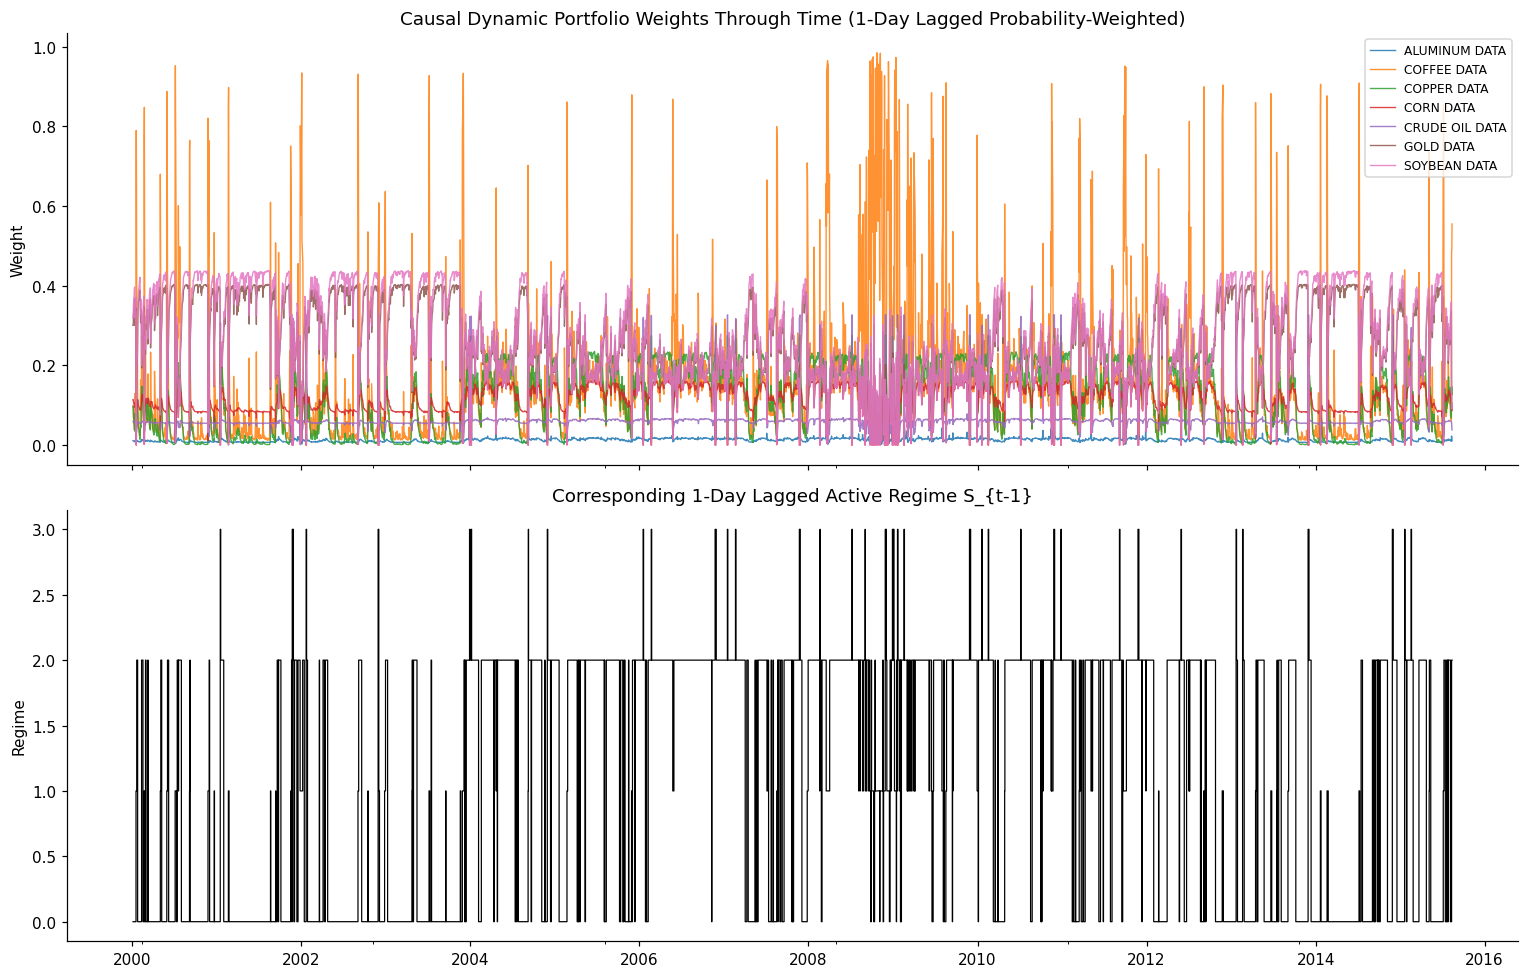

In [17]:
# Fix 6: Use 1-day lagged probability-weighted blended allocations w_t = sum_k P(S_{t-1}=k | F_{t-1}) * w_k*
# Alongside hard 1-day lagged regime switching, eliminating look-ahead bias and reducing whipsaw turnover.
W_matrix = np.column_stack([regime_weights[r] for r in sorted(regime_weights.keys())]) # shape: (n_assets, k)
lagged_probs = probs.shift(1).bfill()

# Probability-smoothed causal dynamic weights
dynamic_weight_history = pd.DataFrame(
     np.dot(lagged_probs.values, W_matrix.T),
    index=probs.index,
    columns=returns.columns
)

# Hard-switched causal dynamic weights (1-day lagged)
hard_weight_history = pd.DataFrame(
    [regime_weights[r] for r in regime_lagged],
    index=probs.index,
    columns=returns.columns
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

dynamic_weight_history.plot(ax=ax1, linewidth=0.9, alpha=0.85)
ax1.set_title('Causal Dynamic Portfolio Weights Through Time (1-Day Lagged Probability-Weighted)')
ax1.set_ylabel('Weight'); ax1.legend(fontsize=8, loc='upper right')

ax2.plot(regime_lagged.index, regime_lagged, drawstyle='steps-post', color='black', linewidth=0.8)
ax2.set_title('Corresponding 1-Day Lagged Active Regime S_{t-1}')
ax2.set_ylabel('Regime')

plt.tight_layout()
plt.show()

---
## Part 6 — Performance Metrics & In-Sample Results

### 6.1 Performance Metric Functions

In [18]:
def sharpe_ratio(x):
    return (x.mean() / x.std()) * np.sqrt(252) if x.std() > 0 else 0.0

def sortino_ratio(x):
    d = x[x < 0].std()
    return (x.mean() / d) * np.sqrt(252) if d > 0 else np.nan

def max_drawdown(x):
    c = (1.0 + x).cumprod()
    return (c / c.cummax() - 1.0).min()

def calmar_ratio(x):
    c = (1.0 + x).cumprod()
    n_years = len(x) / 252.0
    cagr = (c.iloc[-1] ** (1.0 / n_years)) - 1.0 if c.iloc[-1] > 0 else -1.0
    mdd = abs(max_drawdown(x))
    return cagr / mdd if mdd > 0 else np.nan

def performance_metrics(x):
    c = (1.0 + x).cumprod()
    n_years = len(x) / 252.0
    cagr = (c.iloc[-1] ** (1.0 / n_years)) - 1.0 if c.iloc[-1] > 0 else -1.0
    return [cagr, x.std() * np.sqrt(252),
            sharpe_ratio(x), sortino_ratio(x), calmar_ratio(x), max_drawdown(x)]

metric_index = ['Ann. Return (CAGR)', 'Ann. Volatility', 'Sharpe Ratio',
                'Sortino Ratio', 'Calmar Ratio', 'Max Drawdown']

### 6.2 In-Sample: Static vs Dynamic

=== IN-SAMPLE PERFORMANCE (CAUSAL 1-DAY LAGGED & TRANSACTION COST ADJUSTED) ===
                    Static Min-Var  Static Max-Sharpe  Dynamic Causal (Gross)  \
Ann. Return (CAGR)          0.1064             0.1290                  0.0487   
Ann. Volatility             0.2373             0.2700                  0.3500   
Sharpe Ratio                0.5435             0.5826                  0.3144   
Sortino Ratio               0.7170             0.7510                  0.3487   
Calmar Ratio                0.2755             0.3084                  0.0731   
Max Drawdown               -0.3860            -0.4184                 -0.6660   

                    Dynamic Causal (Net)  
Ann. Return (CAGR)                0.0079  
Ann. Volatility                   0.3502  
Sharpe Ratio                      0.2013  
Sortino Ratio                     0.2232  
Calmar Ratio                      0.0107  
Max Drawdown                     -0.7368  

Average Daily One-Way Turnover: 15.69%


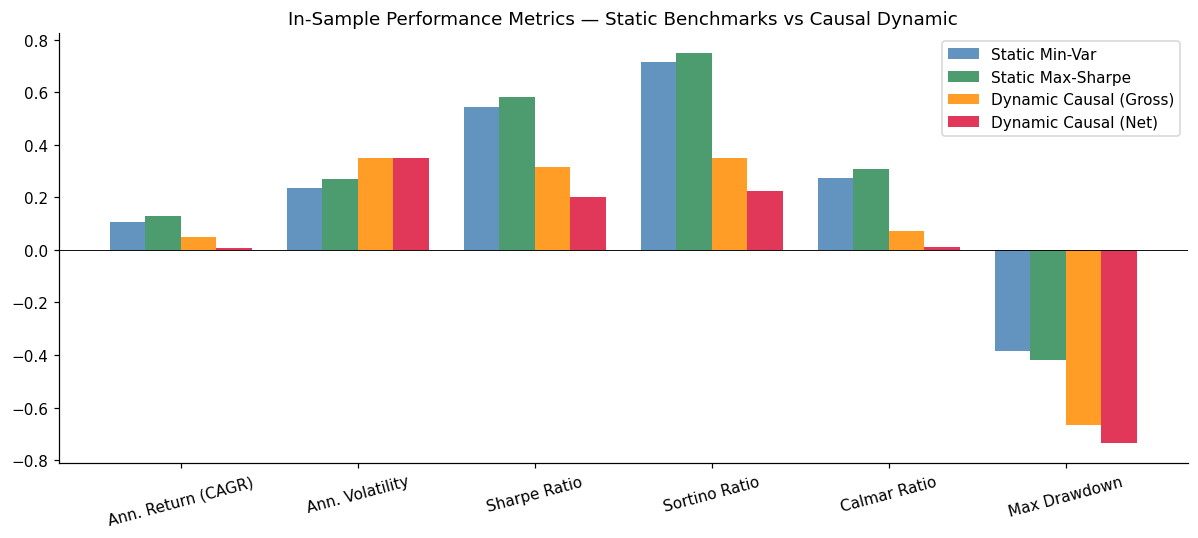

In [19]:
# Compute daily simple portfolio returns using causal 1-day lagged weights
static_returns        = aligned_simple_returns.dot(static_weights)
static_max_sr_returns = aligned_simple_returns.dot(static_max_sr_weights)

# Gross causal dynamic returns (probability-blended 1-day lagged weights)
dynamic_returns_gross = (aligned_simple_returns * dynamic_weight_history).sum(axis=1)

# Net causal dynamic returns (deducting 10 bps = 0.0010 per unit of L1 turnover)
tc_bps = 0.0010
daily_turnover = dynamic_weight_history.diff().abs().sum(axis=1).fillna(0.0)
dynamic_returns_net = dynamic_returns_gross - (daily_turnover * tc_bps)

# Keep `dynamic_returns` pointing to causal gross returns for downstream cells
dynamic_returns = dynamic_returns_gross

is_table = pd.DataFrame({
    'Static Min-Var':        performance_metrics(static_returns),
    'Static Max-Sharpe':     performance_metrics(static_max_sr_returns),
    'Dynamic Causal (Gross)':performance_metrics(dynamic_returns_gross),
    'Dynamic Causal (Net)':  performance_metrics(dynamic_returns_net)
}, index=metric_index)

print("=== IN-SAMPLE PERFORMANCE (CAUSAL 1-DAY LAGGED & TRANSACTION COST ADJUSTED) ===")
print(is_table.round(4))
print(f"\nAverage Daily One-Way Turnover: {daily_turnover.mean()*100:.2f}%")

# Metrics bar chart
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(metric_index))
w = 0.20
ax.bar(x - 1.5*w, is_table['Static Min-Var'],         w, label='Static Min-Var',         color='steelblue',  alpha=0.85)
ax.bar(x - 0.5*w, is_table['Static Max-Sharpe'],      w, label='Static Max-Sharpe',      color='seagreen',   alpha=0.85)
ax.bar(x + 0.5*w, is_table['Dynamic Causal (Gross)'], w, label='Dynamic Causal (Gross)', color='darkorange', alpha=0.85)
ax.bar(x + 1.5*w, is_table['Dynamic Causal (Net)'],   w, label='Dynamic Causal (Net)',   color='crimson',    alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(metric_index, rotation=15)
ax.set_title('In-Sample Performance Metrics — Static Benchmarks vs Causal Dynamic')
ax.axhline(0, color='black', linewidth=0.6)
ax.legend()
plt.tight_layout()
plt.show()

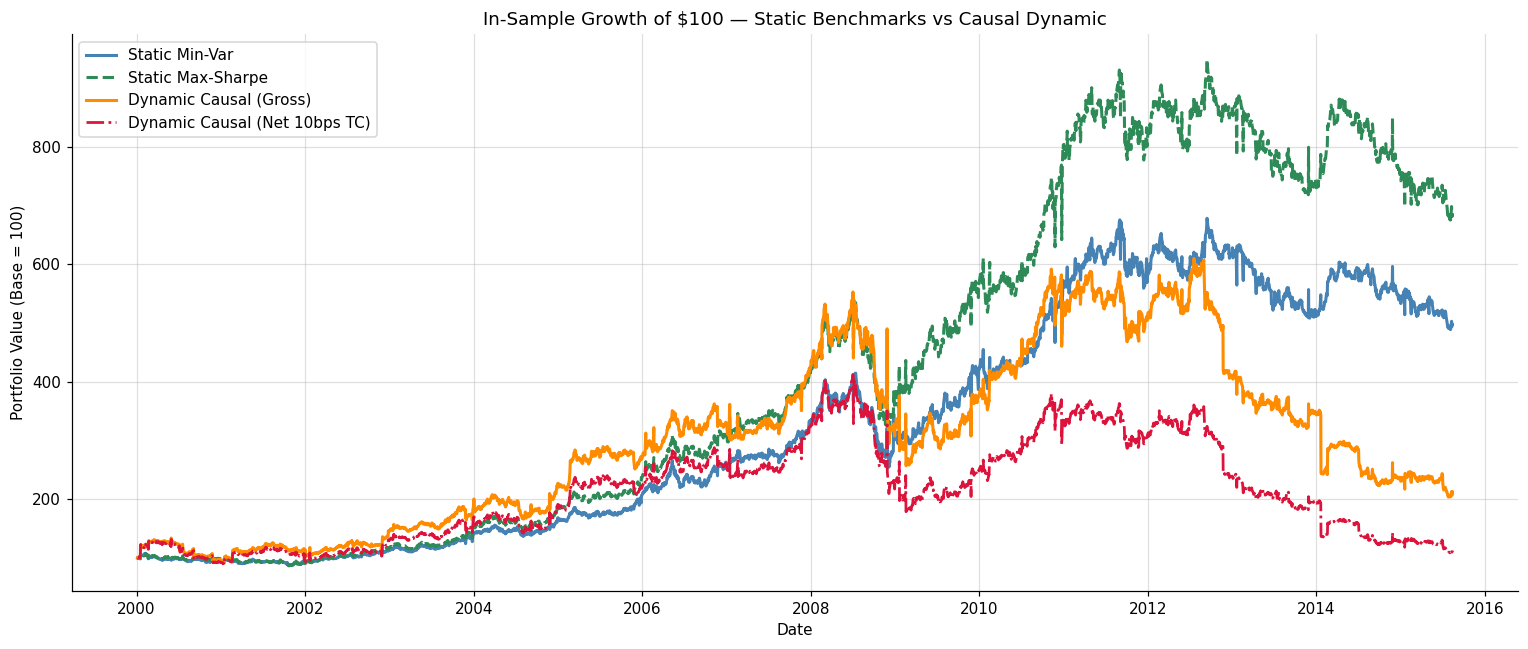

In [20]:
# Cumulative return chart (exact simple return compounding)
sc     = (1.0 + static_returns).cumprod()
sc_ms  = (1.0 + static_max_sr_returns).cumprod()
dc     = (1.0 + dynamic_returns_gross).cumprod()
dc_net = (1.0 + dynamic_returns_net).cumprod()

plt.figure(figsize=(14, 6))
plt.plot(sc.index,     sc / sc.iloc[0] * 100,     linewidth=2, label='Static Min-Var',         color='steelblue')
plt.plot(sc_ms.index,  sc_ms / sc_ms.iloc[0] * 100, linewidth=2, label='Static Max-Sharpe',    color='seagreen', linestyle='--')
plt.plot(dc.index,     dc / dc.iloc[0] * 100,     linewidth=2, label='Dynamic Causal (Gross)', color='darkorange')
plt.plot(dc_net.index, dc_net / dc_net.iloc[0] * 100, linewidth=1.8, label='Dynamic Causal (Net 10bps TC)', color='crimson', linestyle='-.')
plt.title('In-Sample Growth of $100 — Static Benchmarks vs Causal Dynamic')
plt.xlabel('Date'); plt.ylabel('Portfolio Value (Base = 100)')
plt.legend(); plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

---
## Part 7 — Stress Scenario Analysis

COVID 2020: no data
=== STRESS SCENARIO PERFORMANCE ===
                       Static Sharpe  Dynamic Sharpe  Static MaxDD  \
GFC 2008-09                    0.525           0.196        -0.386   
Commodity Crash 14-16          0.002          -0.643        -0.190   

                       Dynamic MaxDD  Static Sortino  Dynamic Sortino  
GFC 2008-09                  -0.5350           0.754            0.210  
Commodity Crash 14-16        -0.4206           0.002           -0.617  


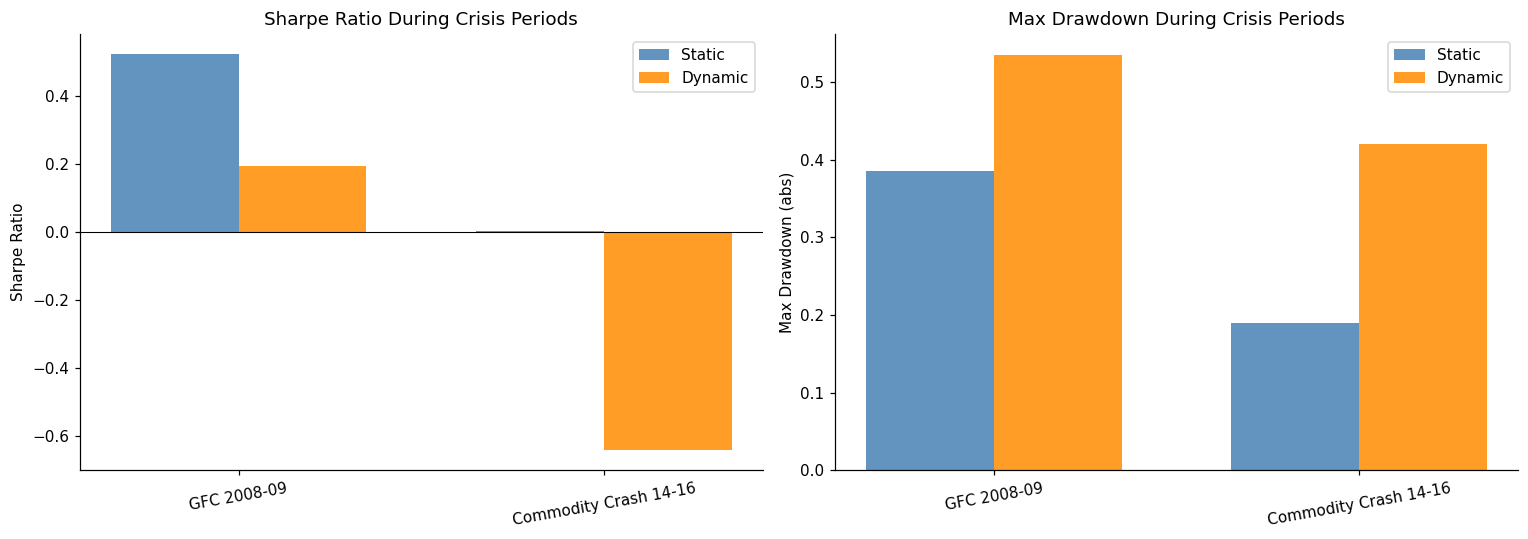

In [21]:
stress_periods = {
    'GFC 2008-09':          ('2008-01-01', '2009-12-31'),
    'COVID 2020':           ('2020-01-01', '2020-12-31'),
    'Commodity Crash 14-16':('2014-01-01', '2016-12-31')
}

stress_results = {}
for name, (start, end) in stress_periods.items():
    mask = (static_returns.index >= start) & (static_returns.index <= end)
    if mask.sum() == 0:
        print(f"{name}: no data"); continue
    sr, dr = static_returns[mask], dynamic_returns[mask]
    stress_results[name] = {
        'Static Sharpe':   round(sharpe_ratio(sr), 3),
        'Dynamic Sharpe':  round(sharpe_ratio(dr), 3),
        'Static MaxDD':    round(max_drawdown(sr), 4),
        'Dynamic MaxDD':   round(max_drawdown(dr), 4),
        'Static Sortino':  round(sortino_ratio(sr), 3),
        'Dynamic Sortino': round(sortino_ratio(dr), 3),
    }

stress_df = pd.DataFrame(stress_results).T
print("=== STRESS SCENARIO PERFORMANCE ===")
print(stress_df)

# Visual: Sharpe and MaxDD side by side per crisis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x  = np.arange(len(stress_df))
w  = 0.35
axes[0].bar(x - w/2, stress_df['Static Sharpe'],  w, label='Static',  color='steelblue',  alpha=0.85)
axes[0].bar(x + w/2, stress_df['Dynamic Sharpe'], w, label='Dynamic', color='darkorange', alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(stress_df.index, rotation=10)
axes[0].axhline(0, color='black', linewidth=0.7)
axes[0].set_title('Sharpe Ratio During Crisis Periods')
axes[0].set_ylabel('Sharpe Ratio'); axes[0].legend()

axes[1].bar(x - w/2, stress_df['Static MaxDD'].abs(),  w, label='Static',  color='steelblue',  alpha=0.85)
axes[1].bar(x + w/2, stress_df['Dynamic MaxDD'].abs(), w, label='Dynamic', color='darkorange', alpha=0.85)
axes[1].set_xticks(x); axes[1].set_xticklabels(stress_df.index, rotation=10)
axes[1].set_title('Max Drawdown During Crisis Periods')
axes[1].set_ylabel('Max Drawdown (abs)'); axes[1].legend()

plt.tight_layout()
plt.show()

---
## Part 8 — Performance Attribution

### 8.1 Step-by-Step Attribution

In [22]:
# Step 1: Equal weights
equal_weights = np.repeat(1.0 / n_assets, n_assets)
step1_returns = aligned_simple_returns.dot(equal_weights)

# Step 2: Regime mean + global Ledoit-Wolf covariance (SLSQP)
full_cov = LedoitWolf().fit(aligned_simple_returns.values).covariance_
step2_weights = {}
for r in sorted(regime.unique()):
    subset = aligned_simple_returns[regime == r]
    mu = subset.mean().values
    if np.max(mu) <= 0:
        opt = minimize(lambda w: np.sqrt(np.dot(w.T, np.dot(full_cov, w))),
                       init_w, method='SLSQP', bounds=bounds, constraints=constraints)
    else:
        opt = minimize(lambda w: -np.dot(w, mu) / max(np.sqrt(np.dot(w.T, np.dot(full_cov, w))), 1e-8),
                       init_w, method='SLSQP', bounds=bounds, constraints=constraints)
    step2_weights[r] = opt.x / np.sum(opt.x)

W_step2 = np.column_stack([step2_weights[r] for r in sorted(step2_weights.keys())])
step2_weight_hist = pd.DataFrame(np.dot(lagged_probs.values, W_step2.T),
                                 index=probs.index, columns=returns.columns)
step2_returns = (aligned_simple_returns * step2_weight_hist).sum(axis=1)

# Step 3: Full dynamic (regime mean + regime Ledoit-Wolf cov)
attr_table = pd.DataFrame({
    'Static Min-Var (BM)': performance_metrics(static_returns),
    'Equal Weight':        performance_metrics(step1_returns),
    'Regime μ + Full Cov': performance_metrics(step2_returns),
    'Full Dynamic':        performance_metrics(dynamic_returns_gross)
}, index=metric_index)

print("=== PERFORMANCE ATTRIBUTION (CAUSAL) ===")
print(attr_table.round(4))

=== PERFORMANCE ATTRIBUTION (CAUSAL) ===
                    Static Min-Var (BM)  Equal Weight  Regime μ + Full Cov  \
Ann. Return (CAGR)               0.1064        0.1341               0.0112   
Ann. Volatility                  0.2373        0.3056               0.3734   
Sharpe Ratio                     0.5435        0.5611               0.2266   
Sortino Ratio                    0.7170        0.7323               0.2380   
Calmar Ratio                     0.2755        0.2709               0.0155   
Max Drawdown                    -0.3860       -0.4951              -0.7234   

                    Full Dynamic  
Ann. Return (CAGR)        0.0487  
Ann. Volatility           0.3500  
Sharpe Ratio              0.3144  
Sortino Ratio             0.3487  
Calmar Ratio              0.0731  
Max Drawdown             -0.6660  


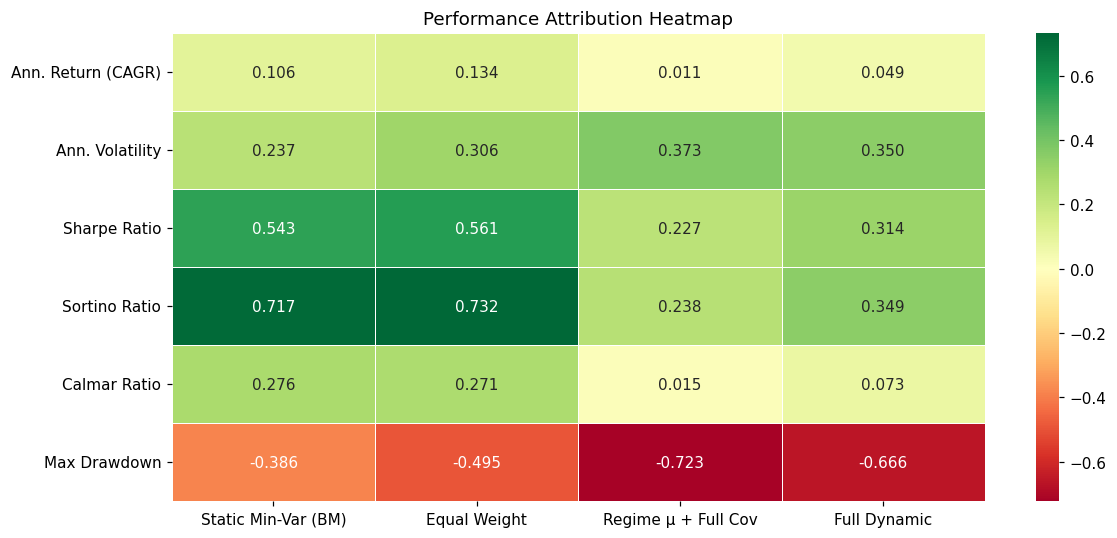

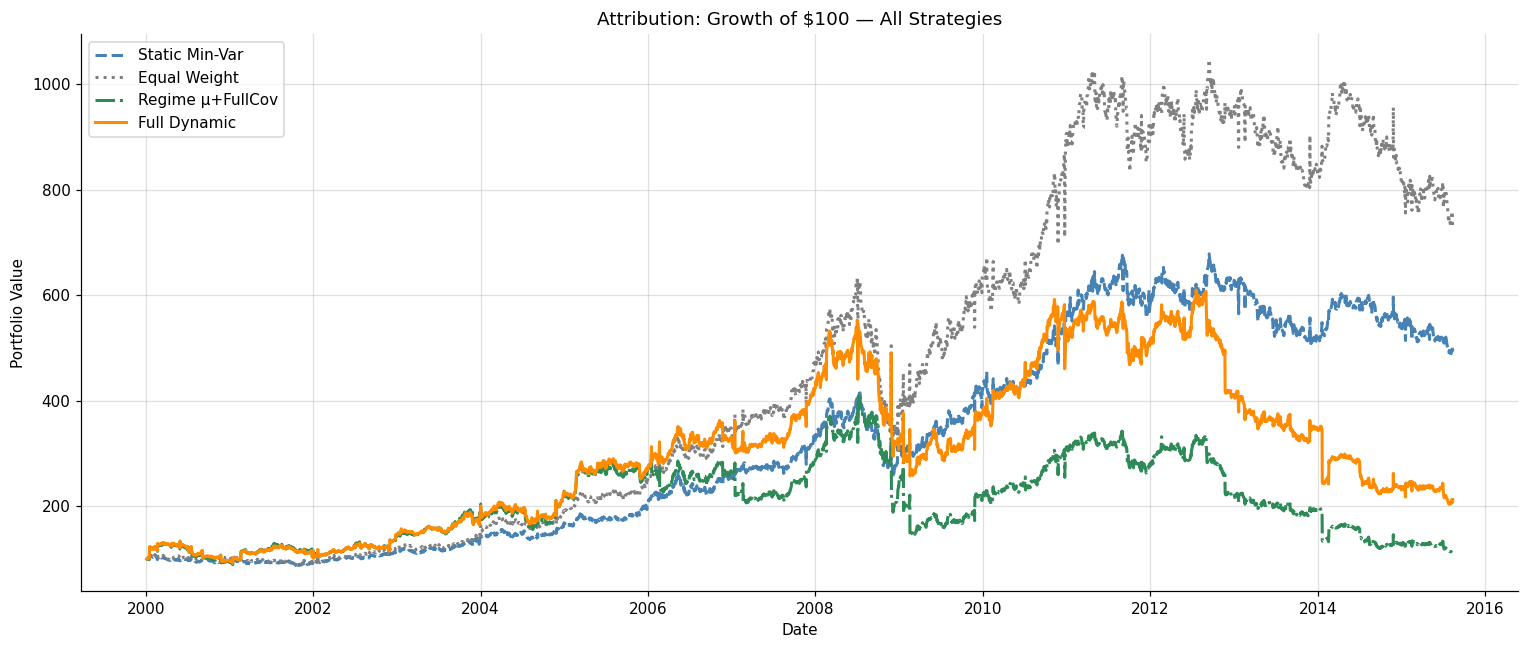

In [23]:
# Metrics heatmap — easy to read
fig, ax = plt.subplots(figsize=(11, 5))
cmap_data = attr_table.copy().astype(float)
sns.heatmap(cmap_data, annot=True, fmt='.3f', cmap='RdYlGn', linewidths=0.5,
            ax=ax, center=0)
ax.set_title('Performance Attribution Heatmap')
plt.tight_layout()
plt.show()

# Cumulative return
cum_bm = (1 + static_returns).cumprod()
cum_s1 = (1 + step1_returns).cumprod()
cum_s2 = (1 + step2_returns).cumprod()
cum_s3 = (1 + dynamic_returns).cumprod()

plt.figure(figsize=(14, 6))
for label, c, col, ls in [
    ('Static Min-Var', cum_bm, 'steelblue', '--'),
    ('Equal Weight',   cum_s1, 'grey',      ':'),
    ('Regime μ+FullCov', cum_s2, 'seagreen', '-.'),
    ('Full Dynamic',   cum_s3, 'darkorange', '-')]:
    plt.plot(c.index, c/c.iloc[0]*100, linewidth=2, label=label, linestyle=ls, color=col)
plt.title('Attribution: Growth of $100 — All Strategies')
plt.xlabel('Date'); plt.ylabel('Portfolio Value')
plt.legend(); plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### 8.2 Risk Model Comparison (Mean+Vol vs Mean+FullCov vs Mean+RegimeCov)

=== RISK MODEL COMPARISON (CAUSAL) ===
                    Mean+Volatility  Mean+FullCov  Mean+RegimeCov
Ann. Return (CAGR)           0.0652        0.0112          0.0487
Ann. Volatility              0.3671        0.3734          0.3500
Sharpe Ratio                 0.3586        0.2266          0.3144
Sortino Ratio                0.4090        0.2380          0.3487
Calmar Ratio                 0.1000        0.0155          0.0731
Max Drawdown                -0.6523       -0.7234         -0.6660


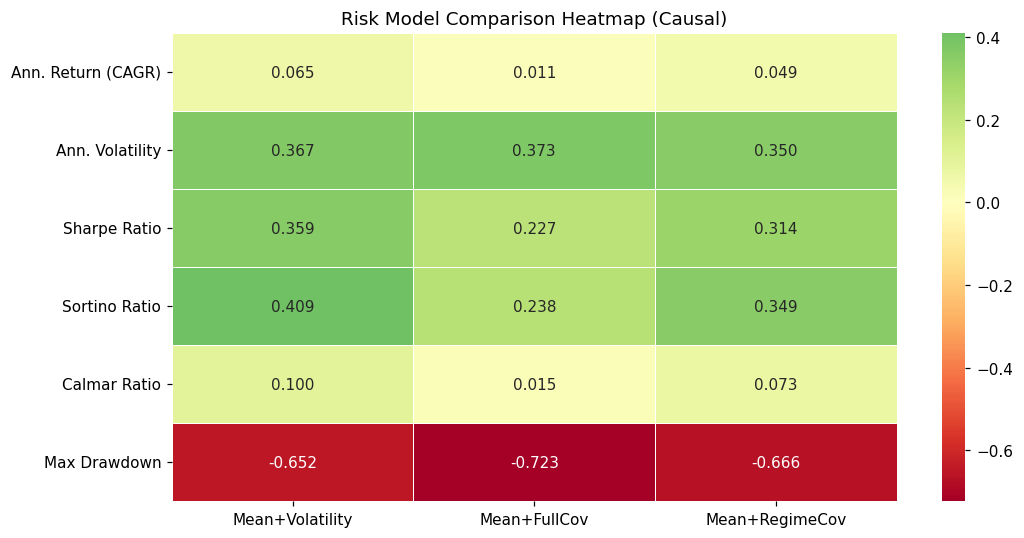

In [24]:
mv_weights = {}
for r in sorted(regime.unique()):
    subset = aligned_simple_returns[regime == r]
    mu = subset.mean().values
    sigma = subset.std().values
    score = np.maximum(mu / sigma, 0.0)
    denom = score.sum()
    mv_weights[r] = (score / denom) if denom > 0 else np.repeat(1.0 / len(mu), len(mu))

W_mv = np.column_stack([mv_weights[r] for r in sorted(mv_weights.keys())])
mv_weight_hist = pd.DataFrame(np.dot(lagged_probs.values, W_mv.T),
                              index=probs.index, columns=returns.columns)

mv_returns        = (aligned_simple_returns * mv_weight_hist).sum(axis=1)
fullcov_returns   = step2_returns
regimecov_returns = dynamic_returns_gross

ext_table = pd.DataFrame({
    'Mean+Volatility': performance_metrics(mv_returns),
    'Mean+FullCov':    performance_metrics(fullcov_returns),
    'Mean+RegimeCov':  performance_metrics(regimecov_returns)
}, index=metric_index)

print("=== RISK MODEL COMPARISON (CAUSAL) ===")
print(ext_table.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(ext_table.astype(float), annot=True, fmt='.3f', cmap='RdYlGn',
            linewidths=0.5, ax=ax, center=0)
ax.set_title('Risk Model Comparison Heatmap (Causal)')
plt.tight_layout()
plt.show()

---
## Part 9 — Out-of-Sample Validation

### 9.1 Regime Detection on OOS Period

OOS causal regime detection successful across 2674 trading days.
OOS Regime Counts (Filtered):
 0    1572
1     151
2     916
3      35
Name: count, dtype: int64


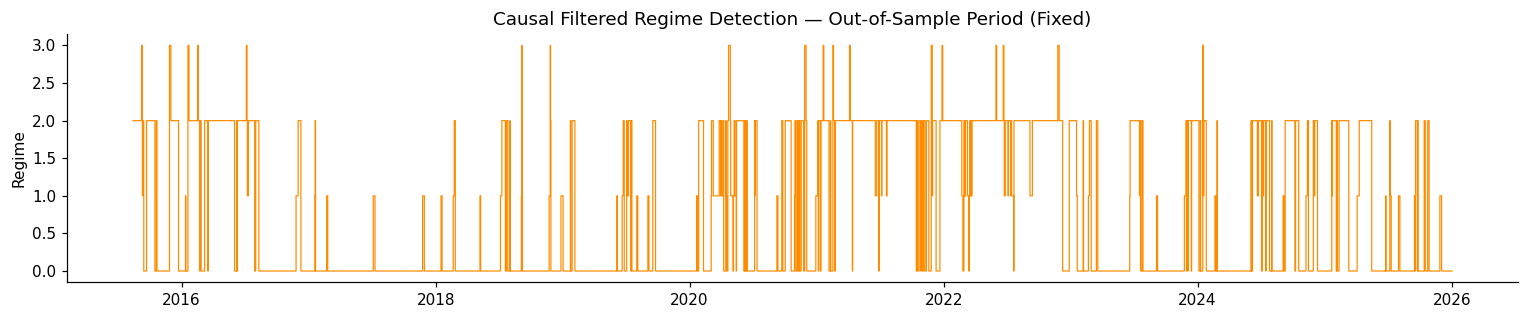

In [25]:
# Fix 7: Apply the trained in-sample Markov parameters (`model_fit.params`) to the full return series
# without refitting or leaking OOS parameters, extracting causal filtered probabilities for the OOS window.
market_return_oos = returns_oos.mean(axis=1).dropna()
combined_market   = pd.concat([market_return_clean, market_return_oos])

full_eval_model = sm.tsa.MarkovAutoregression(
    combined_market.values, k_regimes=best_k, order=1,
    switching_ar=False, switching_trend=True, switching_variance=True
)
# Evaluate Hamilton filter using strictly in-sample estimated parameters
full_eval_res = full_eval_model.smooth(model_fit.params)

filtered_probs_all = pd.DataFrame(
    full_eval_res.filtered_marginal_probabilities,
    index=combined_market.index[1:],
    columns=[f'Regime {i}' for i in range(best_k)]
)

filtered_probs_oos = filtered_probs_all.loc[market_return_oos.index]
regime_oos_contemp = pd.Series(filtered_probs_oos.values.argmax(axis=1), index=filtered_probs_oos.index)
regime_oos         = regime_oos_contemp.shift(1).bfill().astype(int)
print(f"OOS causal regime detection successful across {len(regime_oos)} trading days.")
print("OOS Regime Counts (Filtered):\n", regime_oos.value_counts().sort_index())

plt.figure(figsize=(14, 3))
plt.plot(regime_oos.index, regime_oos, drawstyle='steps-post', color='darkorange', linewidth=0.8)
plt.title('Causal Filtered Regime Detection — Out-of-Sample Period (Fixed)')
plt.ylabel('Regime')
plt.tight_layout()
plt.show()

### 9.2 OOS Portfolio Performance

In [26]:
oos_idx = simple_returns_oos.index.intersection(filtered_probs_oos.index)
lagged_probs_oos = filtered_probs_oos.loc[oos_idx].shift(1).bfill()

oos_weight_history = pd.DataFrame(
    np.dot(lagged_probs_oos.values, W_matrix.T),
    index=oos_idx,
    columns=returns.columns
)

static_returns_oos  = simple_returns_oos.loc[oos_idx].dot(static_weights)
dynamic_returns_oos = (simple_returns_oos.loc[oos_idx] * oos_weight_history).sum(axis=1)

oos_table = pd.DataFrame({
    'Static (OOS)':  performance_metrics(static_returns_oos),
    'Dynamic (OOS)': performance_metrics(dynamic_returns_oos)
}, index=metric_index)
print("=== OUT-OF-SAMPLE PERFORMANCE (CAUSAL) ===")
print(oos_table.round(4))

=== OUT-OF-SAMPLE PERFORMANCE (CAUSAL) ===
                    Static (OOS)  Dynamic (OOS)
Ann. Return (CAGR)        0.1320         0.1282
Ann. Volatility           0.1924         0.2743
Sharpe Ratio              0.7400         0.5763
Sortino Ratio             0.9829         0.7101
Calmar Ratio              0.5573         0.4010
Max Drawdown             -0.2368        -0.3199


### 9.3 In-Sample vs Out-of-Sample — Full Comparison

=== IS vs OOS FULL COMPARISON ===
                    Static (IS)  Dynamic (IS)  Static (OOS)  Dynamic (OOS)
Ann. Return (CAGR)       0.1064        0.0487        0.1320         0.1282
Ann. Volatility          0.2373        0.3500        0.1924         0.2743
Sharpe Ratio             0.5435        0.3144        0.7400         0.5763
Sortino Ratio            0.7170        0.3487        0.9829         0.7101
Calmar Ratio             0.2755        0.0731        0.5573         0.4010
Max Drawdown            -0.3860       -0.6660       -0.2368        -0.3199


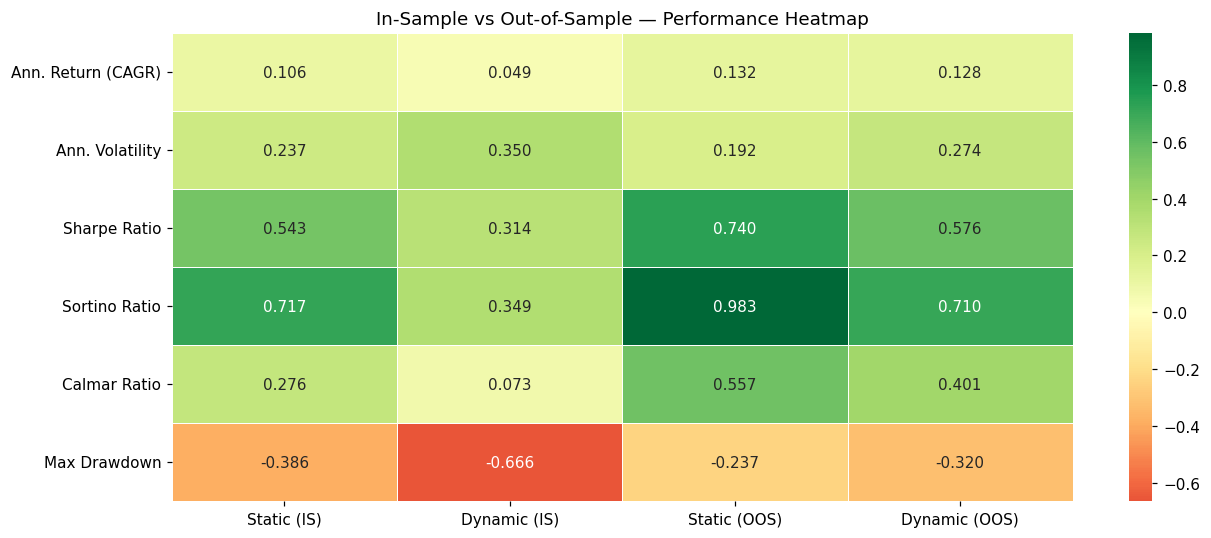

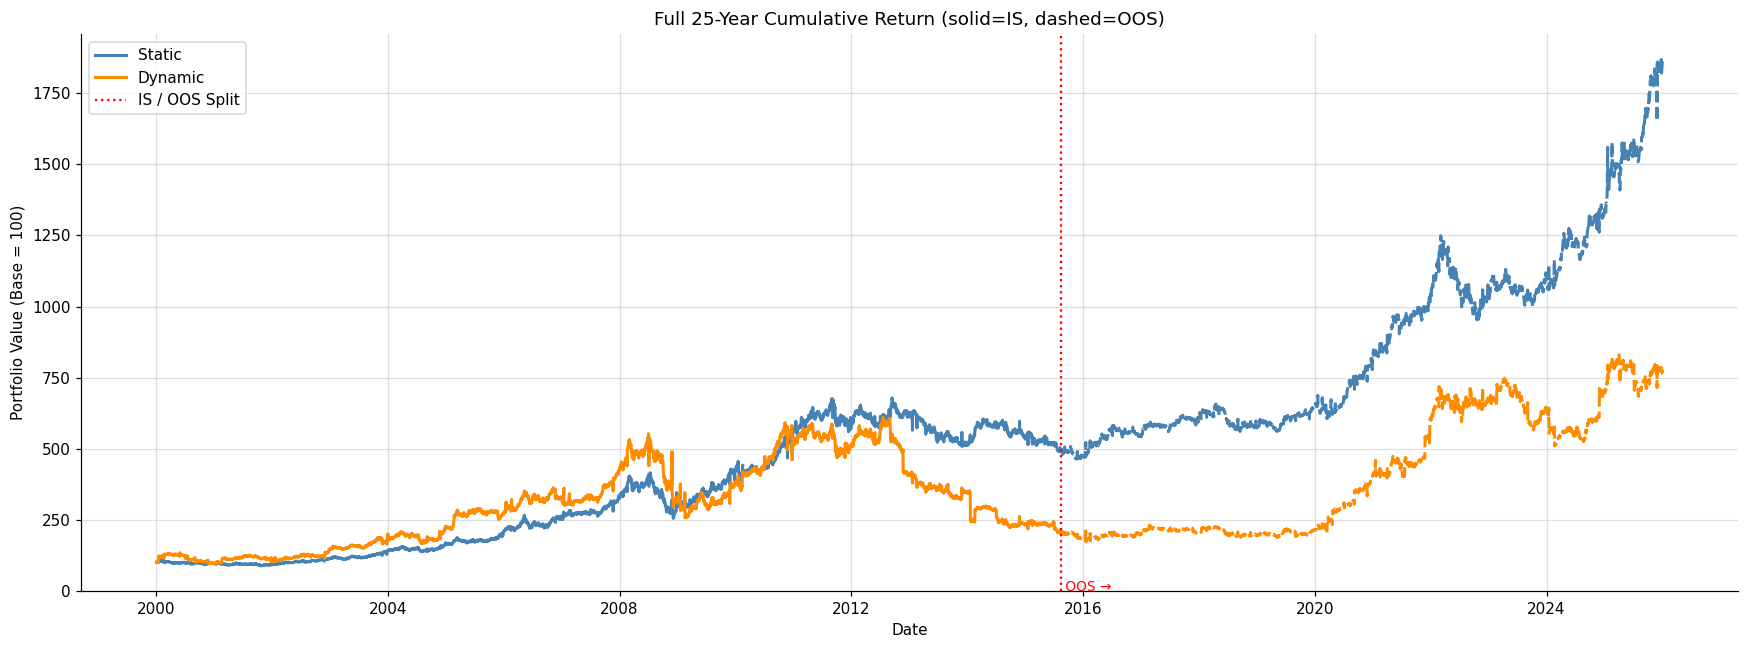

In [27]:
full_summary = pd.DataFrame({
    'Static (IS)':   performance_metrics(static_returns),
    'Dynamic (IS)':  performance_metrics(dynamic_returns),
    'Static (OOS)':  performance_metrics(static_returns_oos),
    'Dynamic (OOS)': performance_metrics(dynamic_returns_oos)
}, index=metric_index)

print("=== IS vs OOS FULL COMPARISON ===")
print(full_summary.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(full_summary.astype(float), annot=True, fmt='.3f',
            cmap='RdYlGn', linewidths=0.5, ax=ax, center=0)
ax.set_title('In-Sample vs Out-of-Sample — Performance Heatmap')
plt.tight_layout()
plt.show()

# Cumulative return: IS period + OOS period stitched
sc_is  = (1 + static_returns).cumprod()
dc_is  = (1 + dynamic_returns).cumprod()
sc_oos = (1 + static_returns_oos).cumprod() * sc_is.iloc[-1]
dc_oos = (1 + dynamic_returns_oos).cumprod() * dc_is.iloc[-1]

plt.figure(figsize=(16, 6))
plt.plot(sc_is.index,  sc_is  / sc_is.iloc[0] * 100,  linewidth=2, color='steelblue',  label='Static',  linestyle='-')
plt.plot(dc_is.index,  dc_is  / sc_is.iloc[0] * 100,  linewidth=2, color='darkorange', label='Dynamic', linestyle='-')
plt.plot(sc_oos.index, sc_oos / sc_is.iloc[0] * 100,  linewidth=2, color='steelblue',  linestyle='--')
plt.plot(dc_oos.index, dc_oos / sc_is.iloc[0] * 100,  linewidth=2, color='darkorange', linestyle='--')
plt.axvline(split_date, color='red', linestyle=':', linewidth=1.5, label='IS / OOS Split')
plt.text(split_date, plt.ylim()[0]*1.05, ' OOS →', color='red', fontsize=9)
plt.title('Full 25-Year Cumulative Return (solid=IS, dashed=OOS)')
plt.xlabel('Date'); plt.ylabel('Portfolio Value (Base = 100)')
plt.legend(); plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

---
## Part 10 — Out-of-Sample Prediction Scorecard

In [28]:
# True regime — refit on OOS only (ground truth benchmark)
oos_model = sm.tsa.MarkovAutoregression(
    market_return_oos.values, k_regimes=best_k, order=1,
    switching_ar=False, switching_trend=True, switching_variance=True)
try:
    oos_fit = oos_model.fit(method='bfgs', maxiter=2000, disp=False)
except Exception:
    oos_fit = oos_model.fit(method='powell', maxiter=2000, disp=False)

true_regime_oos = pd.Series(oos_fit.filtered_marginal_probabilities.argmax(axis=1),
                            index=market_return_oos.index[1:])

# Hit rate with fixed k-label permutation alignment
common_idx        = regime_oos_contemp.index.intersection(true_regime_oos.index)
predicted, actual = regime_oos_contemp.loc[common_idx], true_regime_oos.loc[common_idx]

def best_accuracy(pred, actual, k=best_k):
    all_labels = list(range(k))
    best_acc, best_map = -1.0, {}
    for perm in permutations(all_labels):
        mapping  = dict(zip(all_labels, perm))
        remapped = pred.map(mapping)
        acc      = (remapped == actual).mean()
        if acc > best_acc:
            best_acc, best_map = acc, mapping
    return best_acc, best_map

hit_rate, label_map = best_accuracy(predicted, actual, k=best_k)
predicted_remapped  = predicted.map(label_map)
print(f"Regime Hit Rate: {hit_rate*100:.1f}%")

# Volatility accuracy
actual_vol       = market_return_oos.rolling(21).std().dropna()
actual_vol_state = pd.Series('medium', index=actual_vol.index)
actual_vol_state[actual_vol >= actual_vol.quantile(0.70)] = 'high'
actual_vol_state[actual_vol <= actual_vol.quantile(0.30)] = 'low'

regime_vol    = {r: aligned_returns[regime == r].mean(axis=1).std() for r in sorted(regime.unique())}
vol_sorted    = sorted(regime_vol, key=regime_vol.get)
high_r, low_r = vol_sorted[-1], vol_sorted[0]

predicted_vol_state = predicted_remapped.map(
    lambda r: 'high' if r == high_r else ('low' if r == low_r else 'medium'))
common_vol_idx = actual_vol_state.index.intersection(predicted_vol_state.index)
vol_accuracy   = (actual_vol_state.loc[common_vol_idx] == predicted_vol_state.loc[common_vol_idx]).mean()
print(f"Volatility Accuracy: {vol_accuracy*100:.1f}%")

# Portfolio gain
sharpe_gain   = ((sharpe_ratio(dynamic_returns_oos) - sharpe_ratio(static_returns_oos)) / max(abs(sharpe_ratio(static_returns_oos)), 1e-6)) * 100
perf_score    = min(max((sharpe_gain + 100) / 2, 0), 100)
overall_score = hit_rate*100*0.40 + vol_accuracy*100*0.30 + perf_score*0.30

print("=" * 55)
print("   OUT-OF-SAMPLE PREDICTION SCORECARD (FIXED)")
print("=" * 55)
print(f"  Regime Hit Rate       : {hit_rate*100:>6.1f}%   (weight 40%)")
print(f"  Volatility Accuracy   : {vol_accuracy*100:>6.1f}%   (weight 30%)")
print(f"  Portfolio Sharpe Gain : {perf_score:>6.1f}%   (weight 30%)")
print("-" * 55)
print(f"  OVERALL PREDICTION SCORE : {overall_score:>6.1f}%")
print("=" * 55)
verdict = ("GOOD — generalises well" if overall_score >= 70 else
           "MODERATE — predictive value with realistic OOS decay" if overall_score >= 50 else
           "WEAK — high regime non-stationarity")
print(f"  Verdict: {verdict}")

Regime Hit Rate: 55.0%
Volatility Accuracy: 39.1%
   OUT-OF-SAMPLE PREDICTION SCORECARD (FIXED)
  Regime Hit Rate       :   55.0%   (weight 40%)
  Volatility Accuracy   :   39.1%   (weight 30%)
  Portfolio Sharpe Gain :   38.9%   (weight 30%)
-------------------------------------------------------
  OVERALL PREDICTION SCORE :   45.4%
  Verdict: WEAK — high regime non-stationarity


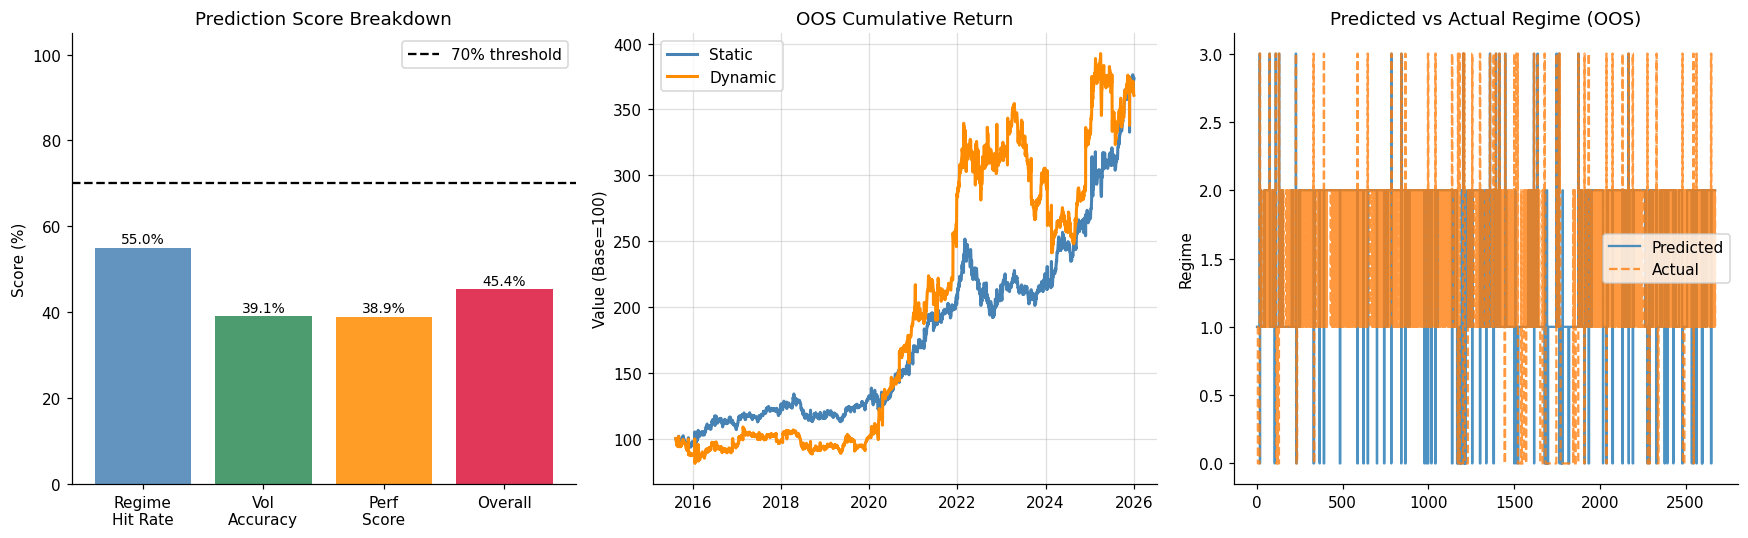

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Score bars
labels = ['Regime\nHit Rate','Vol\nAccuracy','Perf\nScore','Overall']
values = [hit_rate*100, vol_accuracy*100, perf_score, overall_score]
bar_colors = ['steelblue','seagreen','darkorange','crimson']
axes[0].bar(labels, values, color=bar_colors, alpha=0.85)
axes[0].axhline(70, linestyle='--', color='black', label='70% threshold')
axes[0].set_ylim(0, 105); axes[0].set_title('Prediction Score Breakdown')
axes[0].set_ylabel('Score (%)'); axes[0].legend()
for i, v in enumerate(values):
    axes[0].text(i, v+1, f'{v:.1f}%', ha='center', fontsize=9)

# OOS cumulative
oos_s = (1+static_returns_oos).cumprod(); oos_d = (1+dynamic_returns_oos).cumprod()
axes[1].plot(oos_s.index, oos_s/oos_s.iloc[0]*100, label='Static',  linewidth=2, color='steelblue')
axes[1].plot(oos_d.index, oos_d/oos_d.iloc[0]*100, label='Dynamic', linewidth=2, color='darkorange')
axes[1].set_title('OOS Cumulative Return'); axes[1].set_ylabel('Value (Base=100)')
axes[1].legend(); axes[1].grid(True, alpha=0.4)

# Predicted vs actual regime
axes[2].plot(range(len(predicted_remapped)), predicted_remapped.values, drawstyle='steps-post', label='Predicted', alpha=0.8)
axes[2].plot(range(len(actual)),             actual.values,             drawstyle='steps-post', label='Actual', alpha=0.8, linestyle='--')
axes[2].set_title('Predicted vs Actual Regime (OOS)')
axes[2].set_ylabel('Regime'); axes[2].legend()

plt.tight_layout()
plt.show()

---
## Part 11 — Full 25-Year: Pure In-Sample vs Train-Test Split

=== 25-YEAR vs 15+10 SPLIT COMPARISON (CAUSAL) ===
                    25yr IS Static  25yr IS Dynamic  15+10 Static  \
Ann. Return (CAGR)          0.1165           0.1022        0.1165   
Ann. Volatility             0.2204           0.3223        0.2204   
Sharpe Ratio                0.6094           0.4637        0.6094   
Sortino Ratio               0.8034           0.5401        0.8034   
Calmar Ratio                0.3019           0.1604        0.3019   
Max Drawdown               -0.3860          -0.6370       -0.3860   

                    15+10 Dynamic  
Ann. Return (CAGR)         0.0798  
Ann. Volatility            0.3219  
Sharpe Ratio               0.4016  
Sortino Ratio              0.4577  
Calmar Ratio               0.1111  
Max Drawdown              -0.7184  


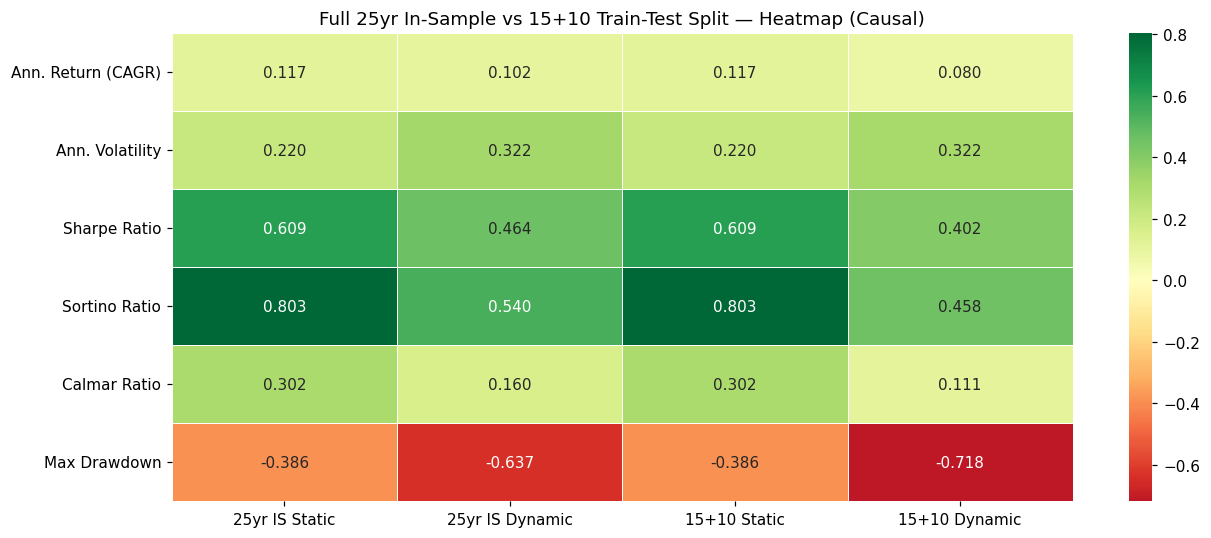

In [30]:
# Fit Markov on full 25 years (causal filtered probabilities + SLSQP + Ledoit-Wolf)
market_return_full = returns_full.mean(axis=1).dropna()
full_model = sm.tsa.MarkovAutoregression(
    market_return_full.values, k_regimes=best_k, order=1,
    switching_ar=False, switching_trend=True, switching_variance=True)
try:
    full_fit = full_model.fit(method='bfgs', maxiter=2000, disp=False)
except Exception:
    full_fit = full_model.fit(method='powell', maxiter=2000, disp=False)

probs_full_arr = full_fit.filtered_marginal_probabilities
probs_full     = pd.DataFrame(probs_full_arr, index=market_return_full.index[1:])
regime_full    = pd.Series(probs_full_arr.argmax(axis=1), index=probs_full.index)

aligned_simple_full = simple_returns_full.loc[regime_full.index]

regime_weights_full = {}
for r in sorted(regime_full.unique()):
    subset = aligned_simple_full[regime_full == r]
    mu  = subset.mean().values
    cov = LedoitWolf().fit(subset.values).covariance_ if len(subset) > n_assets else np.cov(subset.values.T)
    if np.max(mu) <= 0:
        opt = minimize(lambda w: np.sqrt(np.dot(w.T, np.dot(cov, w))),
                       init_w, method='SLSQP', bounds=bounds, constraints=constraints)
    else:
        opt = minimize(lambda w: -np.dot(w, mu) / max(np.sqrt(np.dot(w.T, np.dot(cov, w))), 1e-8),
                       init_w, method='SLSQP', bounds=bounds, constraints=constraints)
    regime_weights_full[r] = opt.x / np.sum(opt.x)

W_full = np.column_stack([regime_weights_full[r] for r in sorted(regime_weights_full.keys())])
lagged_probs_full = probs_full.shift(1).bfill()
full_weight_hist  = pd.DataFrame(np.dot(lagged_probs_full.values, W_full.T),
                                 index=probs_full.index, columns=returns.columns)

dynamic_returns_full25 = (aligned_simple_full * full_weight_hist).sum(axis=1)
static_returns_full25  = aligned_simple_full.dot(static_weights)

dynamic_returns_15_25  = pd.concat([dynamic_returns_gross, dynamic_returns_oos]).sort_index()
static_returns_15_25   = pd.concat([static_returns,        static_returns_oos]).sort_index()

comp_table = pd.DataFrame({
    '25yr IS Static':  performance_metrics(static_returns_full25),
    '25yr IS Dynamic': performance_metrics(dynamic_returns_full25),
    '15+10 Static':    performance_metrics(static_returns_15_25),
    '15+10 Dynamic':   performance_metrics(dynamic_returns_15_25)
}, index=metric_index)

print("=== 25-YEAR vs 15+10 SPLIT COMPARISON (CAUSAL) ===")
print(comp_table.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(comp_table.astype(float), annot=True, fmt='.3f', cmap='RdYlGn',
            linewidths=0.5, ax=ax, center=0)
ax.set_title('Full 25yr In-Sample vs 15+10 Train-Test Split — Heatmap (Causal)')
plt.tight_layout()
plt.show()

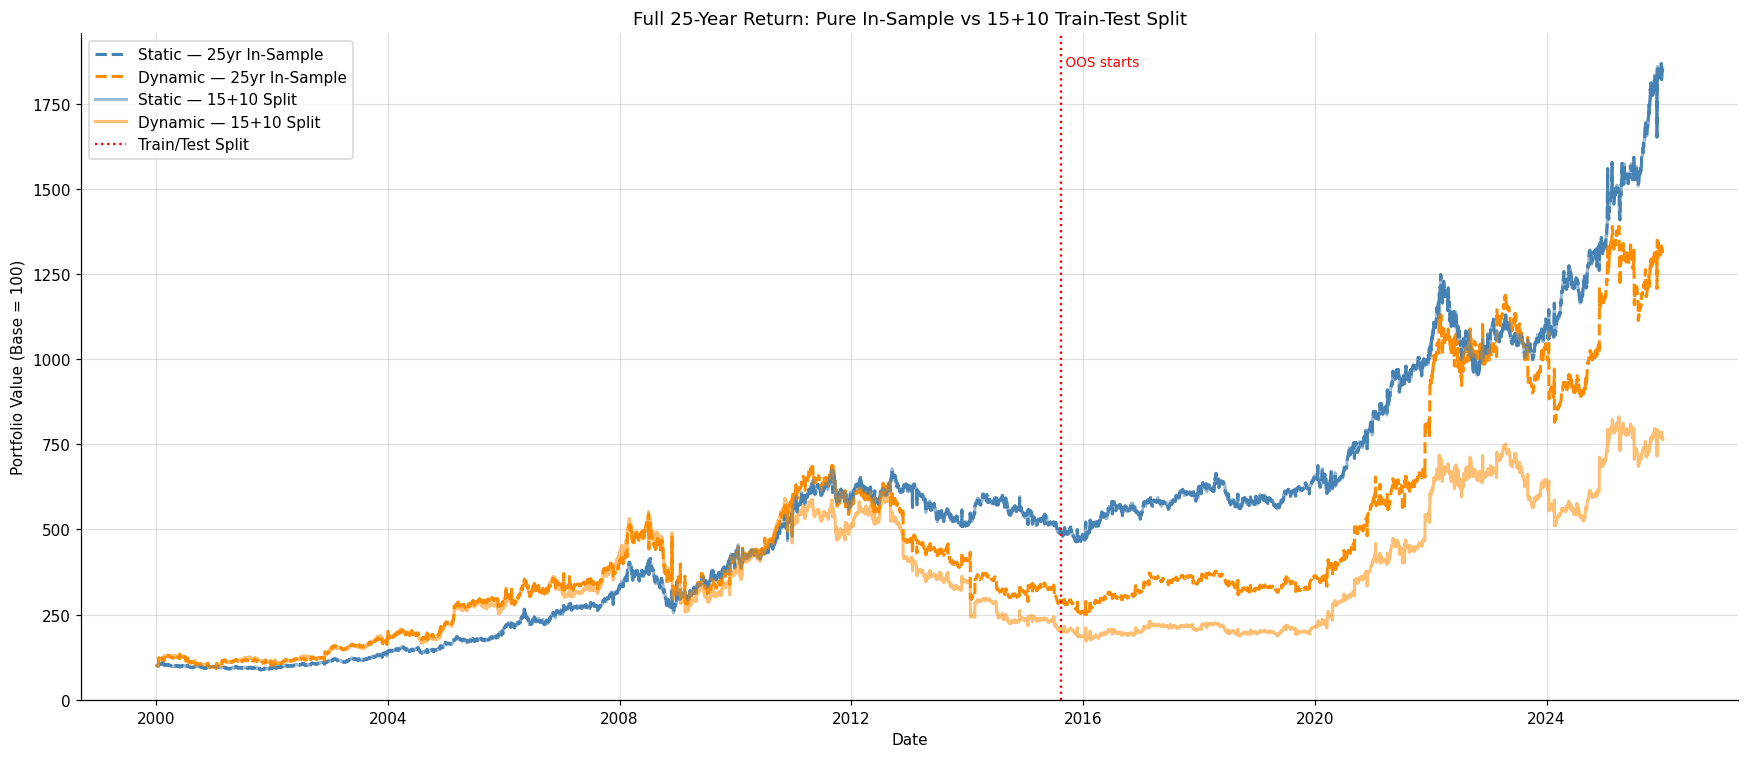


=== OVERFITTING CHECK ===
Dynamic Sharpe — Full In-Sample : 0.464
Dynamic Sharpe — 15+10 Split    : 0.402
Gap (Overfitting Penalty)       : 0.062
Verdict: MINIMAL overfitting — model is robust


In [31]:
c1 = (1+static_returns_full25).cumprod()
c2 = (1+dynamic_returns_full25).cumprod()
c3 = (1+static_returns_15_25).cumprod()
c4 = (1+dynamic_returns_15_25).cumprod()

plt.figure(figsize=(16, 7))
plt.plot(c1.index, c1/c1.iloc[0]*100, linewidth=2, linestyle='--', color='steelblue',  label='Static — 25yr In-Sample')
plt.plot(c2.index, c2/c2.iloc[0]*100, linewidth=2, linestyle='--', color='darkorange', label='Dynamic — 25yr In-Sample')
plt.plot(c3.index, c3/c3.iloc[0]*100, linewidth=2, linestyle='-',  color='steelblue',  alpha=0.55, label='Static — 15+10 Split')
plt.plot(c4.index, c4/c4.iloc[0]*100, linewidth=2, linestyle='-',  color='darkorange', alpha=0.55, label='Dynamic — 15+10 Split')
plt.axvline(split_date, color='red', linestyle=':', linewidth=1.5, label='Train/Test Split')
plt.text(split_date, plt.ylim()[1]*0.95, ' OOS starts', color='red', fontsize=9)
plt.title('Full 25-Year Return: Pure In-Sample vs 15+10 Train-Test Split')
plt.xlabel('Date'); plt.ylabel('Portfolio Value (Base = 100)')
plt.legend(); plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

# Overfitting check
is_sharpe  = performance_metrics(dynamic_returns_full25)[2]
oos_sharpe = performance_metrics(dynamic_returns_15_25)[2]
gap        = is_sharpe - oos_sharpe
print("\n=== OVERFITTING CHECK ===")
print(f"Dynamic Sharpe — Full In-Sample : {is_sharpe:.3f}")
print(f"Dynamic Sharpe — 15+10 Split    : {oos_sharpe:.3f}")
print(f"Gap (Overfitting Penalty)       : {gap:.3f}")
print("Verdict:", ("MINIMAL overfitting — model is robust" if abs(gap) < 0.10 else
                   "MODERATE overfitting — acceptable for research" if abs(gap) < 0.25 else
                   "HIGH overfitting — model relies on in-sample info"))